<a href="https://www.kaggle.com/code/lalit7881/anime-dataset-eda-99?scriptVersionId=358532346" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn  as sns 
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/darkbarrierhub/anime-dataset-2026/anime-dataset-2026.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/darkbarrierhub/anime-dataset-2026/anime-dataset-2026.csv")

In [3]:
df.head()

,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi, Adult Cast, Space","Crime is timeless. By the year 2071, humanity ...",TV,26,"Apr 3, 1998 to Apr 24, 1999",...,Sunrise,Original,24 min. per ep.,R - 17+ (violence & profanity),50,41,90976,1077271,2089081,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi, Adult Cast, Space","Another day, another bounty—such is the life o...",Movie,1,"Sep 1, 2001",...,Bones,Original,1 hr. 55 min.,R - 17+ (violence & profanity),252,663,1827,234731,417292,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi, Adult Cast, Shounen","Vash the Stampede is the man with a $$60,000,0...",TV,26,"Apr 1, 1998 to Sep 30, 1998",...,Madhouse,Manga,24 min. per ep.,PG-13 - Teens 13 or older,433,268,17956,405835,846067,https://cdn.myanimelist.net/images/anime/1130/...
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),7.24,"Action, Drama, Mystery, Supernatural, Detective","Though hidden away from the general public, Wi...",TV,26,"Jul 3, 2002 to Dec 25, 2002",...,Sunrise,Original,25 min. per ep.,PG-13 - Teens 13 or older,3558,2003,720,46691,132072,https://cdn.myanimelist.net/images/anime/10/19...
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,6.97,"Action, Adventure, Fantasy, Shounen",It is the dark century and the people are suff...,TV,52,"Sep 30, 2004 to Sep 29, 2005",...,Toei Animation,Manga,23 min. per ep.,PG - Children,5016,6031,18,6983,16793,https://cdn.myanimelist.net/images/anime/7/215...


In [4]:
df.tail()

,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
30758,65097,AIYOU,AIYOU,AIYOU,UNKNOWN,Music,Music video for the song AIYOU by Eve. The son...,Music,1,"Oct 2, 2026",...,UNKNOWN,Original,2 min.,PG-13 - Teens 13 or older,0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1900/...
30759,65098,22 Durnham Dew,UNKNOWN,22 Durnham Dew,UNKNOWN,"Slice of Life, Music",Music video for the song 22 Durnham Dew by Ben...,Music,1,"Jul 28, 2026",...,UNKNOWN,Original,1 min.,G - All Ages,UNKNOWN,30608,0,UNKNOWN,16,https://cdn.myanimelist.net/images/anime/1045/...
30760,65099,"Ghost (Music, 2026)",UNKNOWN,GHOST,UNKNOWN,"Sci-Fi, Music, Racing","Music video for the song Ghost by lIlBOI, BIG ...",Music,1,"Oct 2, 2026",...,UNKNOWN,Original,3 min.,PG-13 - Teens 13 or older,UNKNOWN,30605,0,UNKNOWN,21,https://cdn.myanimelist.net/images/anime/1833/...
30761,65100,Angels on the Dancefloor,UNKNOWN,Angels On The Dancefloor,UNKNOWN,"Music, Video Game",Music video for the song Angels On The Dancefl...,Music,1,"May 29, 2026",...,Mimoid,Original,4 min.,PG-13 - Teens 13 or older,UNKNOWN,30607,0,UNKNOWN,18,https://cdn.myanimelist.net/images/anime/1845/...
30762,65101,Goemul,Monster,괴물,UNKNOWN,Music,Music video for the song Goemul by WE GO-6.,Music,1,"Sep 22, 2026",...,UNKNOWN,Original,3 min.,PG-13 - Teens 13 or older,0,0,0,UNKNOWN,0,https://cdn.myanimelist.net/images/anime/1239/...


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30763 entries, 0 to 30762
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   anime_id      30763 non-null  int64 
 1   Name          30763 non-null  object
 2   English name  30763 non-null  object
 3   Other name    30763 non-null  object
 4   Score         30763 non-null  object
 5   Genres        30763 non-null  object
 6   Synopsis      30763 non-null  object
 7   Type          30763 non-null  object
 8   Episodes      30763 non-null  object
 9   Aired         30763 non-null  object
 10  Premiered     30763 non-null  object
 11  Status        30763 non-null  object
 12  Producers     30763 non-null  object
 13  Licensors     30763 non-null  object
 14  Studios       30763 non-null  object
 15  Source        30763 non-null  object
 16  Duration      30763 non-null  object
 17  Rating        30182 non-null  object
 18  Rank          30763 non-null  object
 19  Popu

In [6]:
df.describe()

,anime_id,Popularity,Favorites,Members
count,30763.000000,30763.000000,30763.000000,3.076300e+04
mean,35685.588597,15227.872867,429.174528,3.919286e+04
std,20237.227396,8880.868068,4582.160441,1.709663e+05
min,1.000000,0.000000,0.000000,0.000000e+00
25%,17684.000000,7535.500000,0.000000,2.410000e+02
50%,39329.000000,15227.000000,1.000000,1.051000e+03
75%,53047.500000,22918.000000,17.000000,9.162000e+03
max,65101.000000,30608.000000,256516.000000,4.434071e+06


In [7]:
df.isnull().sum()

anime_id          0
Name              0
English name      0
Other name        0
Score             0
Genres            0
Synopsis          0
Type              0
Episodes          0
Aired             0
Premiered         0
Status            0
Producers         0
Licensors         0
Studios           0
Source            0
Duration          0
Rating          581
Rank              0
Popularity        0
Favorites         0
Scored By         0
Members           0
Image URL         0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

anime_id         int64
Name            object
English name    object
Other name      object
Score           object
Genres          object
Synopsis        object
Type            object
Episodes        object
Aired           object
Premiered       object
Status          object
Producers       object
Licensors       object
Studios         object
Source          object
Duration        object
Rating          object
Rank            object
Popularity       int64
Favorites        int64
Scored By       object
Members          int64
Image URL       object
dtype: object

In [10]:
df.shape

(30763, 24)

In [11]:
df.columns

Index(['anime_id', 'Name', 'English name', 'Other name', 'Score', 'Genres',
       'Synopsis', 'Type', 'Episodes', 'Aired', 'Premiered', 'Status',
       'Producers', 'Licensors', 'Studios', 'Source', 'Duration', 'Rating',
       'Rank', 'Popularity', 'Favorites', 'Scored By', 'Members', 'Image URL'],
      dtype='object')

In [12]:
df.nunique()

anime_id        30763
Name            30753
English name    13567
Other name      29559
Score             571
Genres           5666
Synopsis        25439
Type               10
Episodes          264
Aired           18299
Premiered         255
Status              3
Producers        5660
Licensors         336
Studios          2117
Source             17
Duration          345
Rating              6
Rank            17894
Popularity      24708
Favorites        2059
Scored By        9527
Members         12827
Image URL       30558
dtype: int64

## EDA

ANIME DATASET OVERVIEW
Dataset shape: (30763, 24)
Number of rows: 30763
Number of columns: 24

Column names:
 ['anime_id', 'Name', 'English name', 'Other name', 'Score', 'Genres', 'Synopsis', 'Type', 'Episodes', 'Aired', 'Premiered', 'Status', 'Producers', 'Licensors', 'Studios', 'Source', 'Duration', 'Rating', 'Rank', 'Popularity', 'Favorites', 'Scored By', 'Members', 'Image URL']

First 5 records:


,anime_id,Name,English name,Other name,Score,Genres,Synopsis,Type,Episodes,Aired,...,Studios,Source,Duration,Rating,Rank,Popularity,Favorites,Scored By,Members,Image URL
0,1,Cowboy Bebop,Cowboy Bebop,カウボーイビバップ,8.75,"Action, Award Winning, Sci-Fi, Adult Cast, Space","Crime is timeless. By the year 2071, humanity ...",TV,26,"Apr 3, 1998 to Apr 24, 1999",...,Sunrise,Original,24 min. per ep.,R - 17+ (violence & profanity),50,41,90976,1077271,2089081,https://cdn.myanimelist.net/images/anime/4/196...
1,5,Cowboy Bebop: Tengoku no Tobira,Cowboy Bebop: The Movie,カウボーイビバップ 天国の扉,8.38,"Action, Sci-Fi, Adult Cast, Space","Another day, another bounty—such is the life o...",Movie,1,"Sep 1, 2001",...,Bones,Original,1 hr. 55 min.,R - 17+ (violence & profanity),252,663,1827,234731,417292,https://cdn.myanimelist.net/images/anime/1439/...
2,6,Trigun,Trigun,トライガン,8.22,"Action, Adventure, Sci-Fi, Adult Cast, Shounen","Vash the Stampede is the man with a $$60,000,0...",TV,26,"Apr 1, 1998 to Sep 30, 1998",...,Madhouse,Manga,24 min. per ep.,PG-13 - Teens 13 or older,433,268,17956,405835,846067,https://cdn.myanimelist.net/images/anime/1130/...
3,7,Witch Hunter Robin,Witch Hunter Robin,Witch Hunter ROBIN (ウイッチハンターロビン),7.24,"Action, Drama, Mystery, Supernatural, Detective","Though hidden away from the general public, Wi...",TV,26,"Jul 3, 2002 to Dec 25, 2002",...,Sunrise,Original,25 min. per ep.,PG-13 - Teens 13 or older,3558,2003,720,46691,132072,https://cdn.myanimelist.net/images/anime/10/19...
4,8,Bouken Ou Beet,Beet the Vandel Buster,冒険王ビィト,6.97,"Action, Adventure, Fantasy, Shounen",It is the dark century and the people are suff...,TV,52,"Sep 30, 2004 to Sep 29, 2005",...,Toei Animation,Manga,23 min. per ep.,PG - Children,5016,6031,18,6983,16793,https://cdn.myanimelist.net/images/anime/7/215...



Data types:


,Data Type
anime_id,int64
Name,object
English name,object
Other name,object
Score,object
Genres,object
Synopsis,object
Type,object
Episodes,object
Aired,object



Missing values:


,Missing Values
Rating,581



Duplicate rows: 0


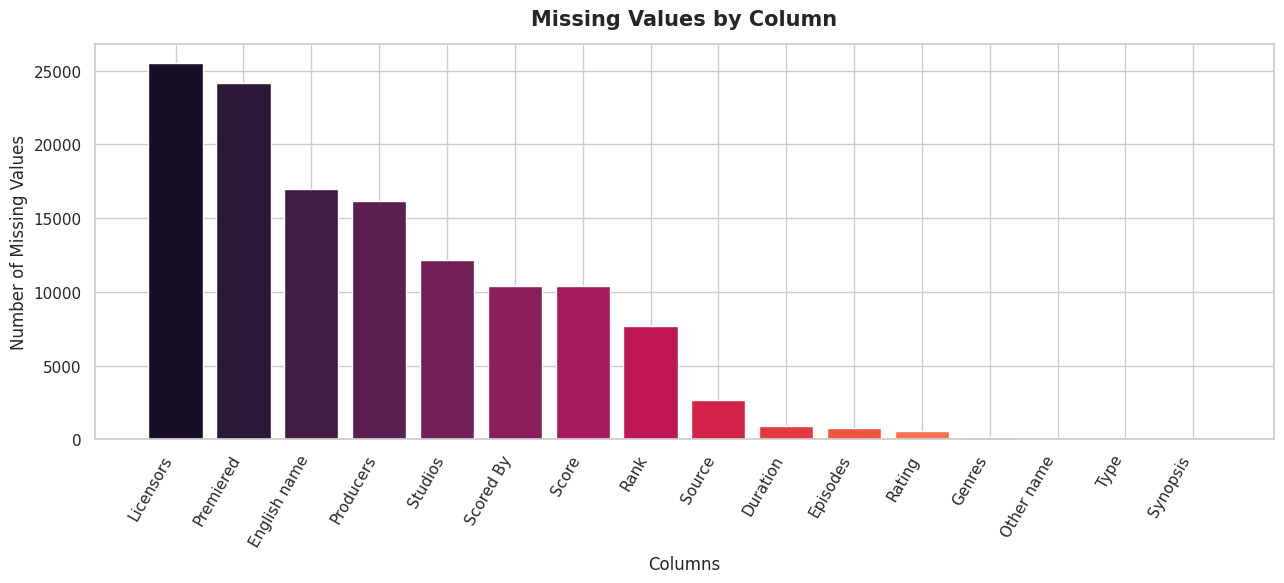

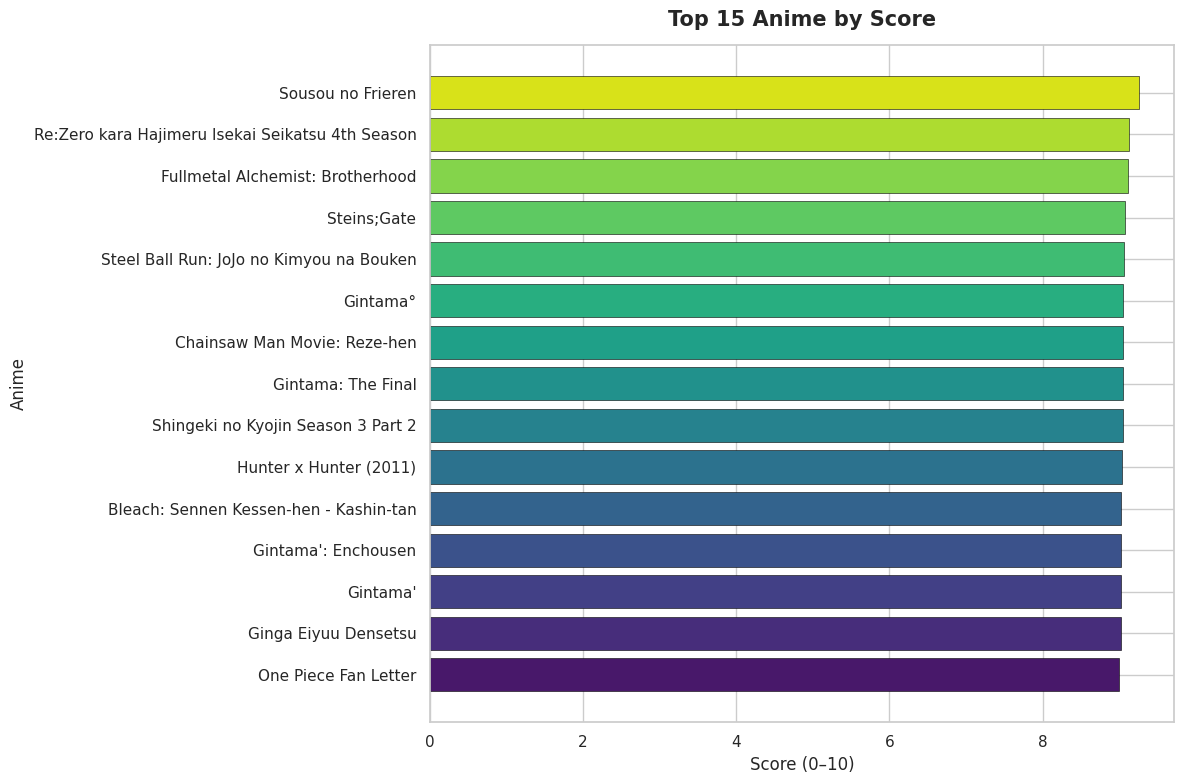

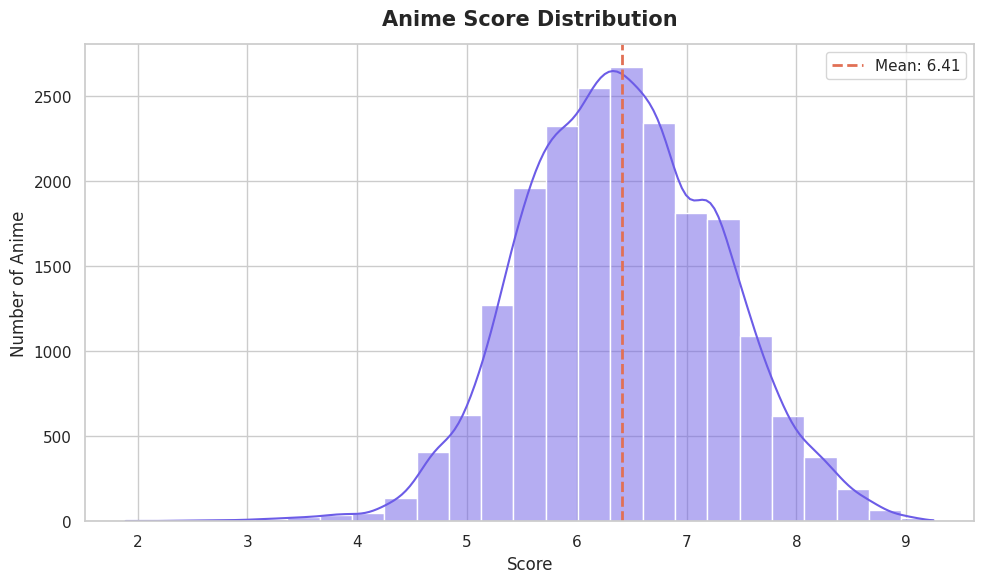

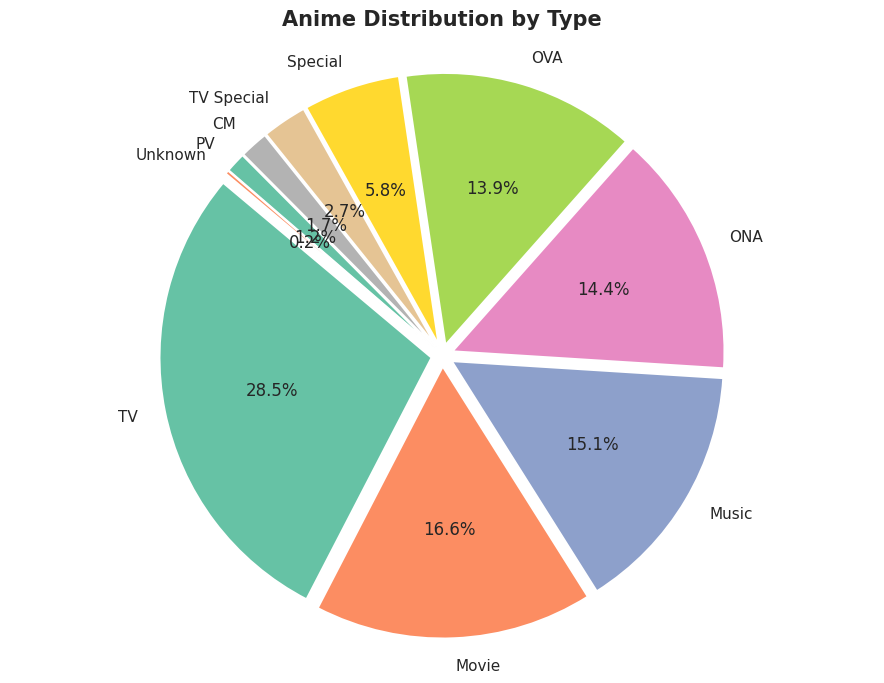

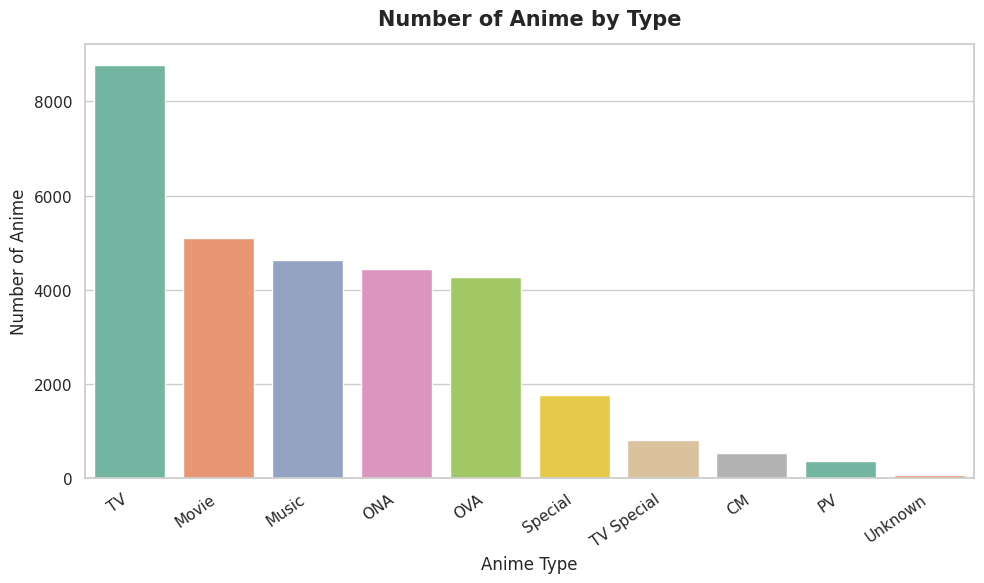

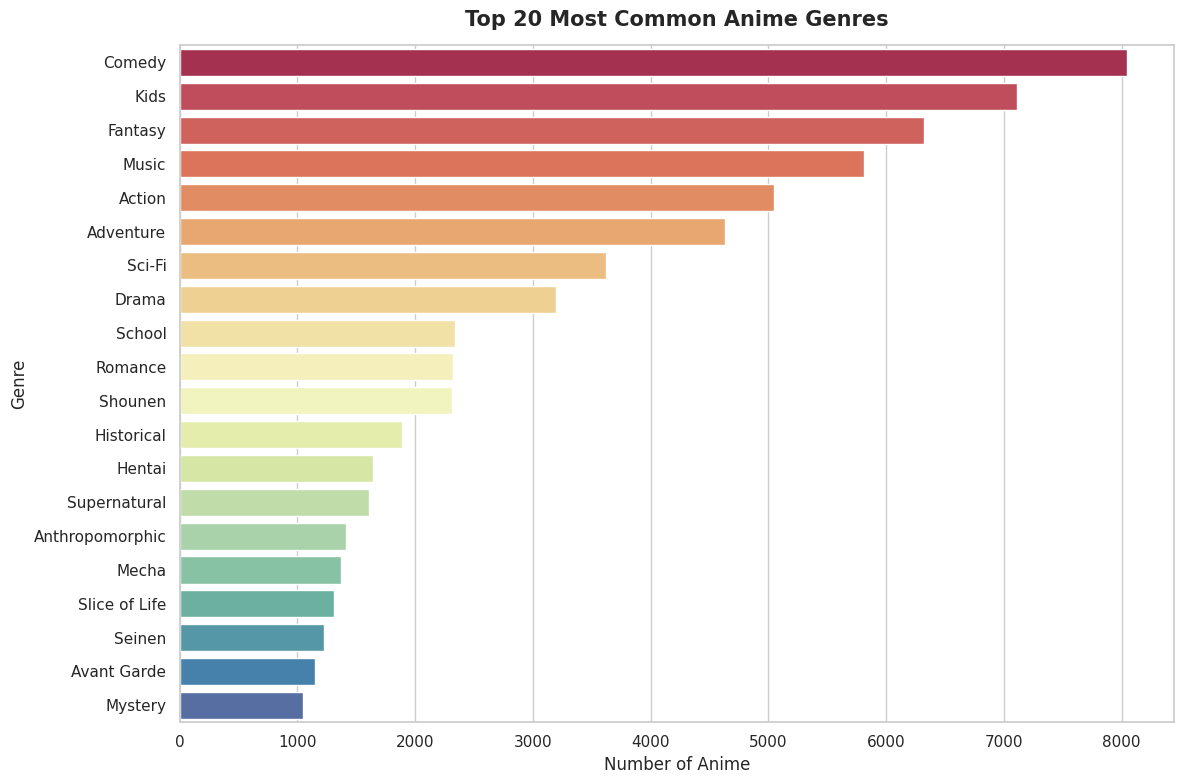

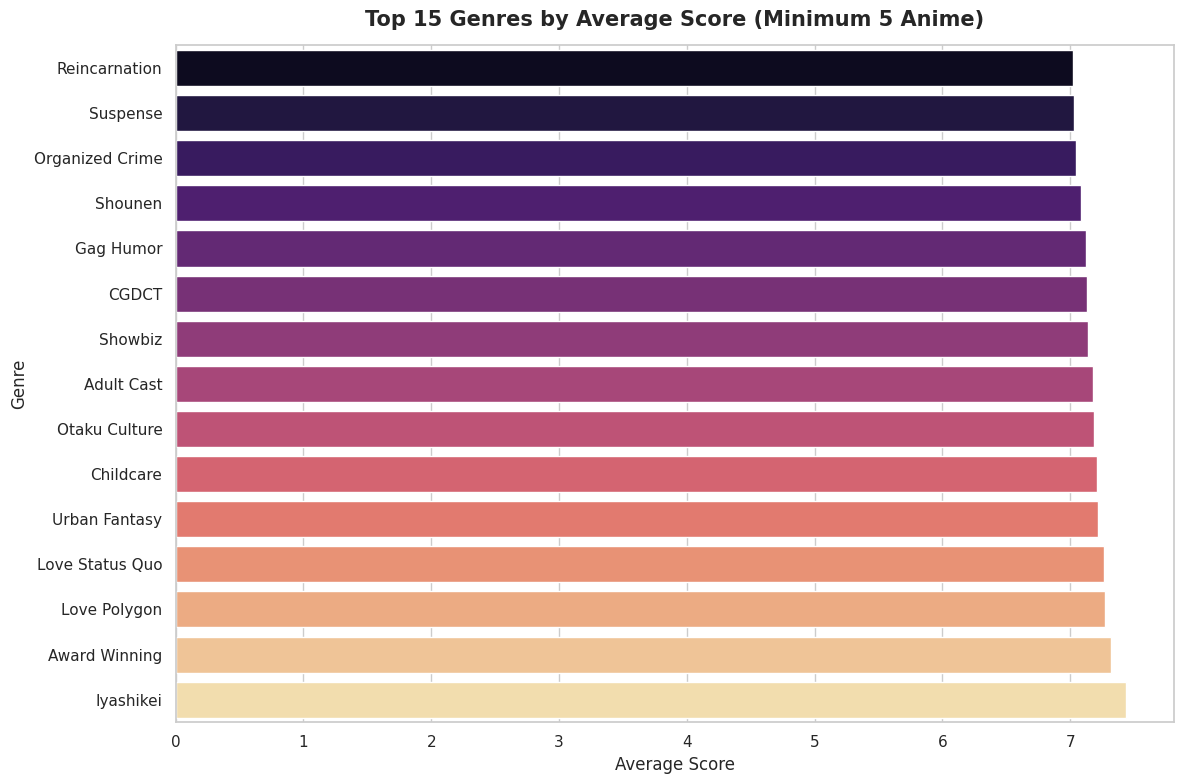

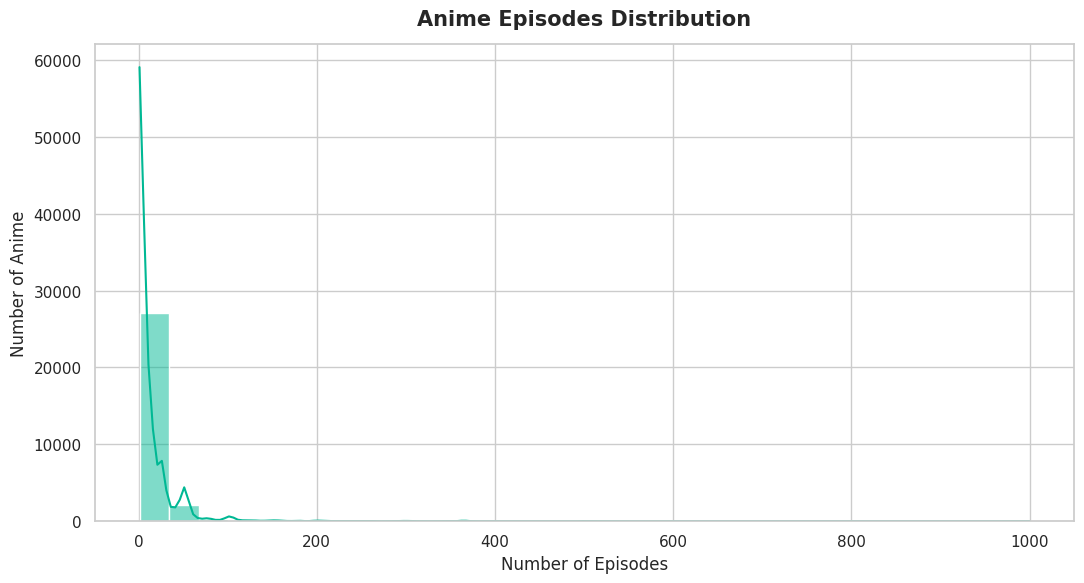

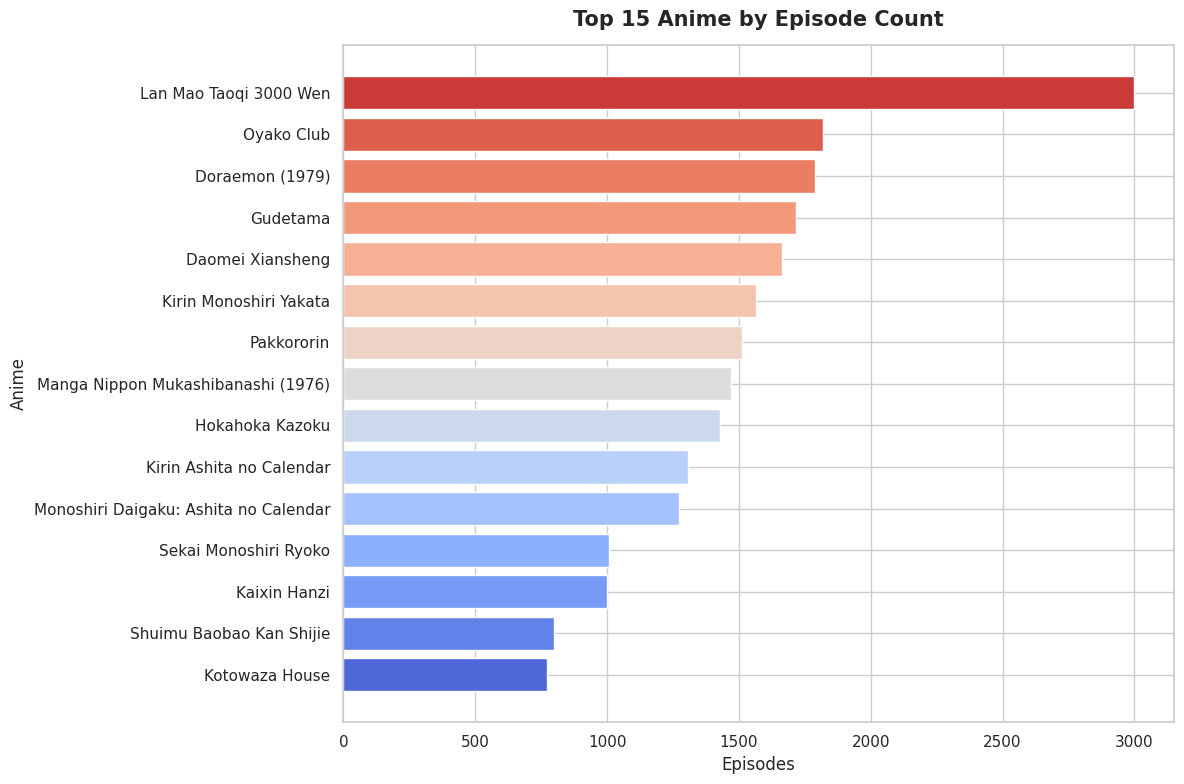

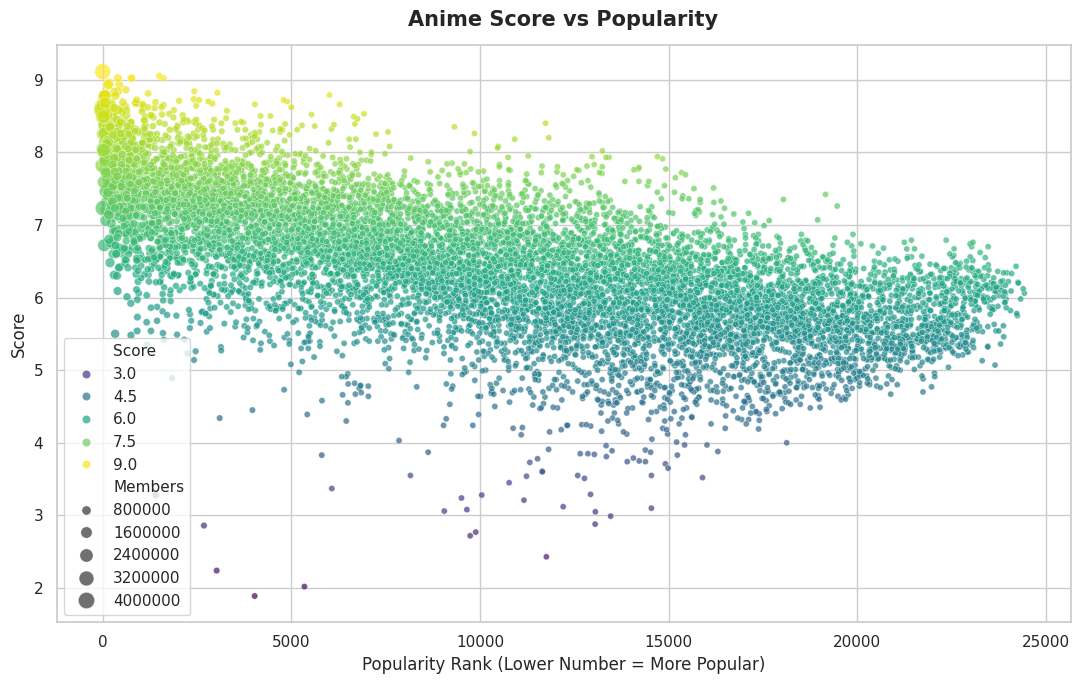

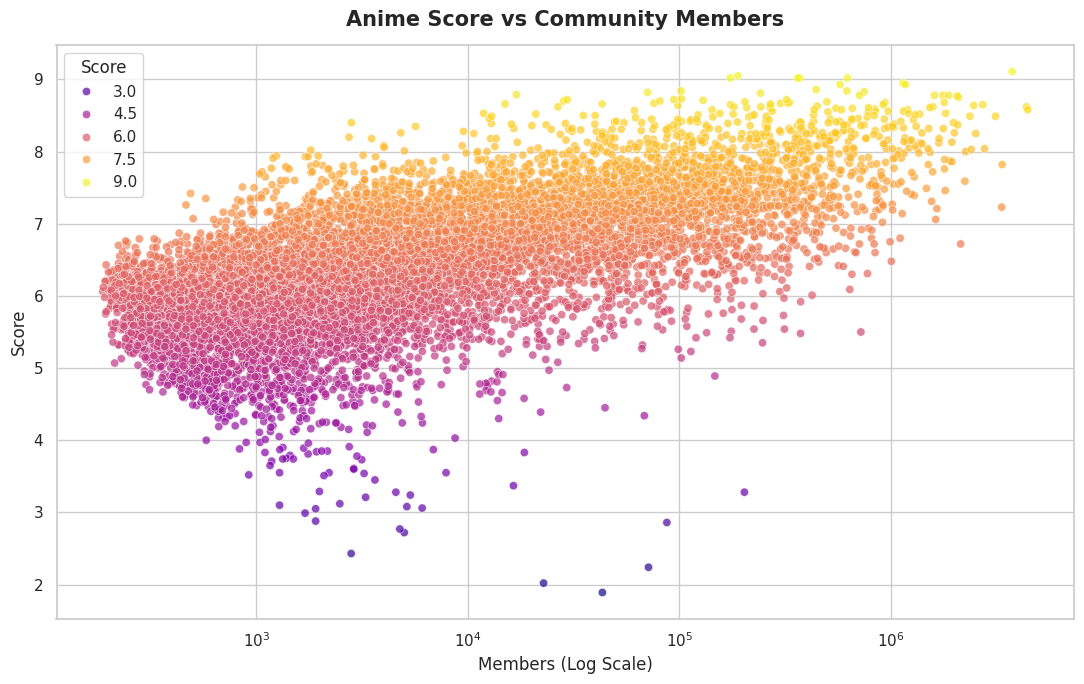

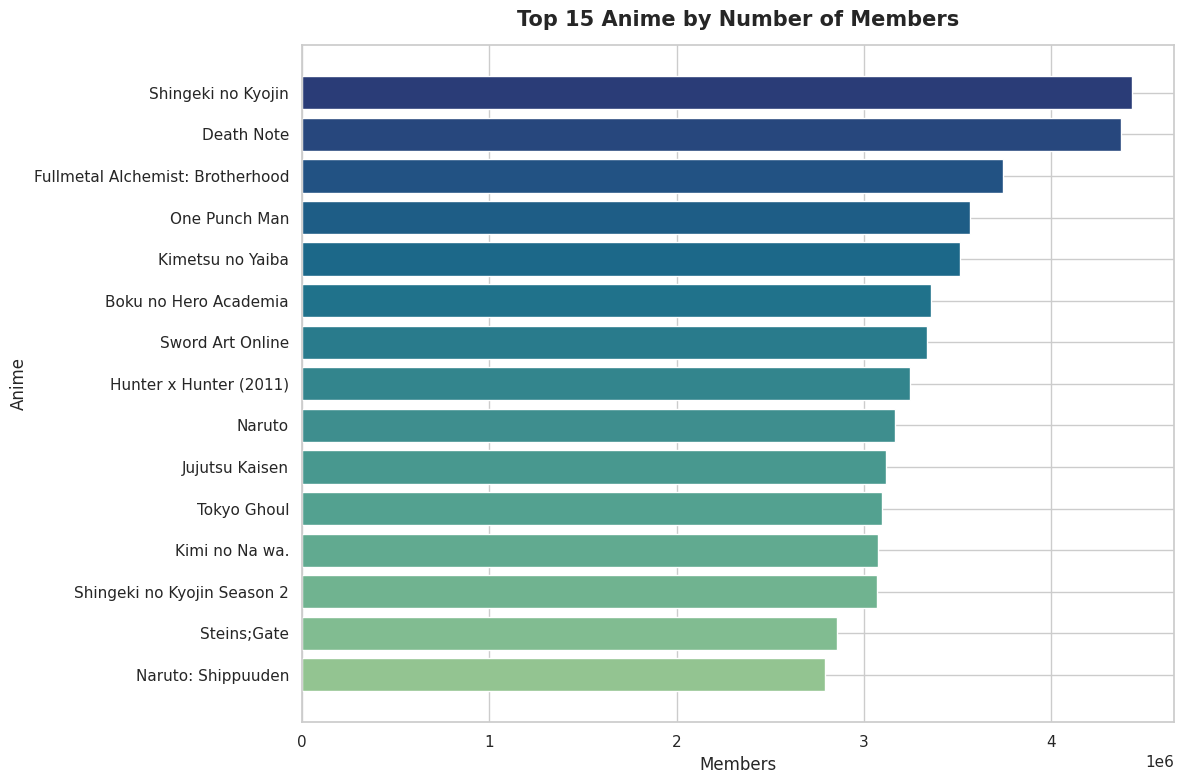

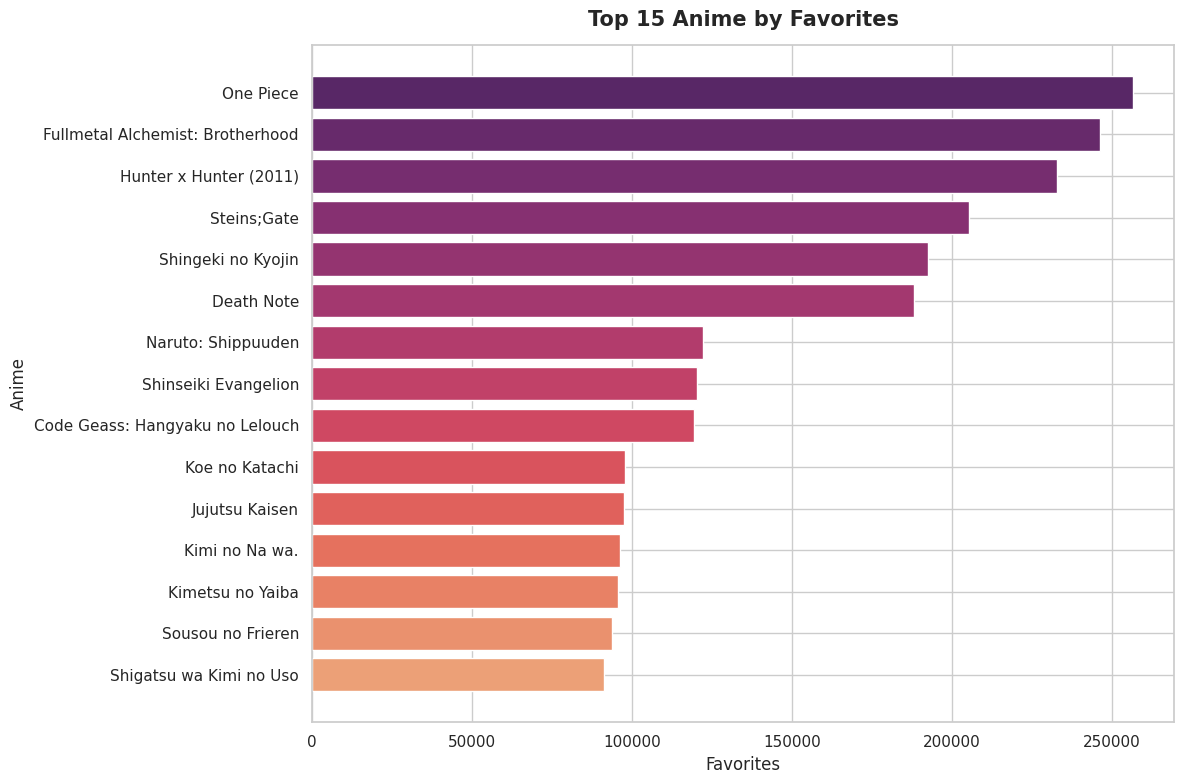

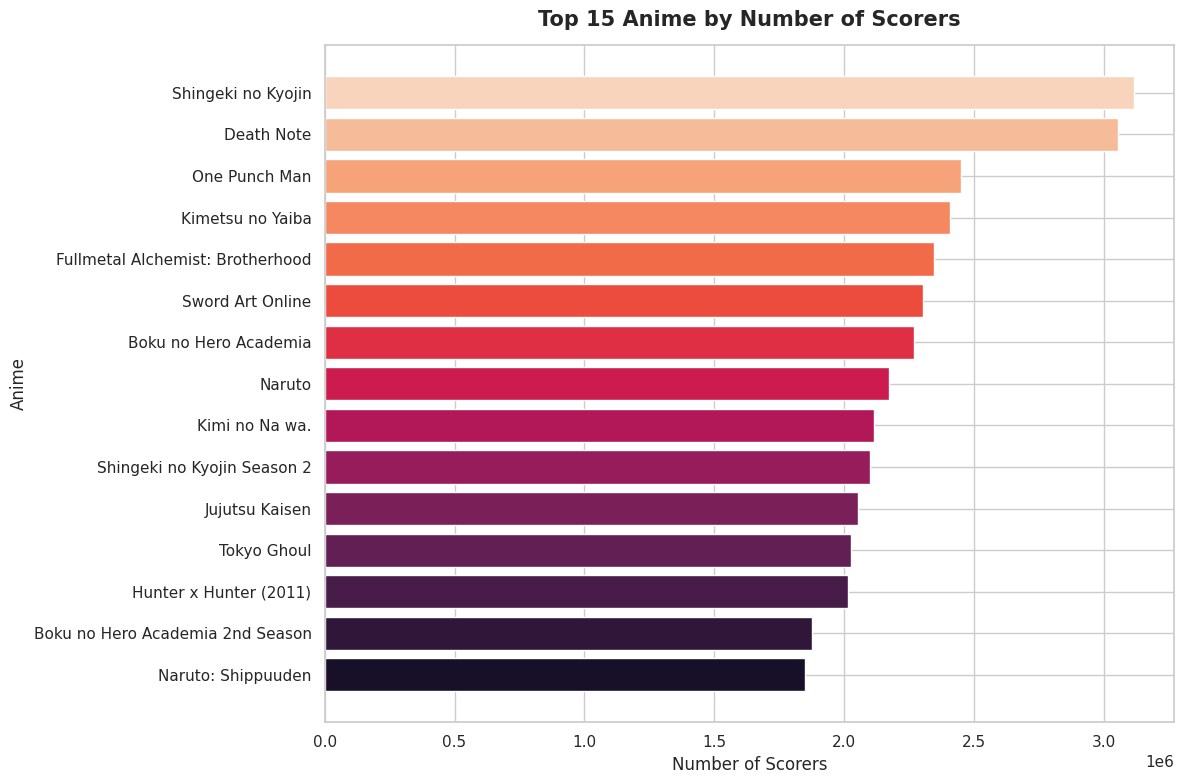

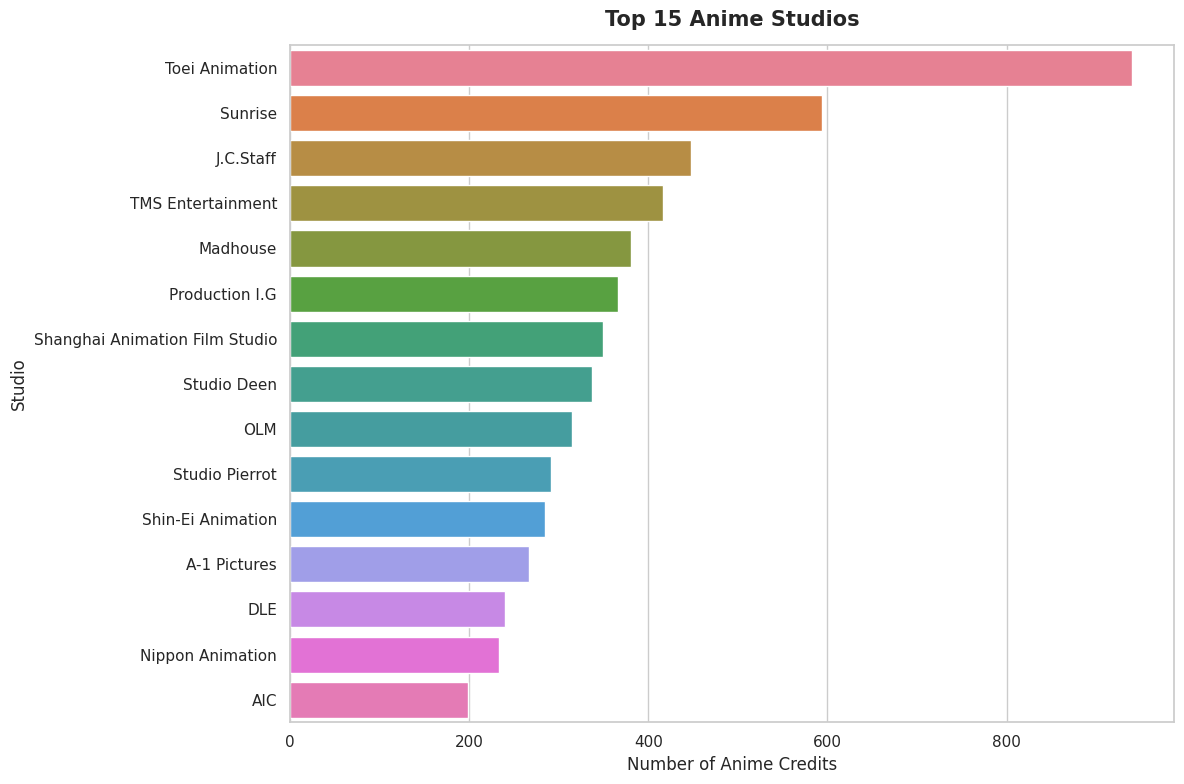

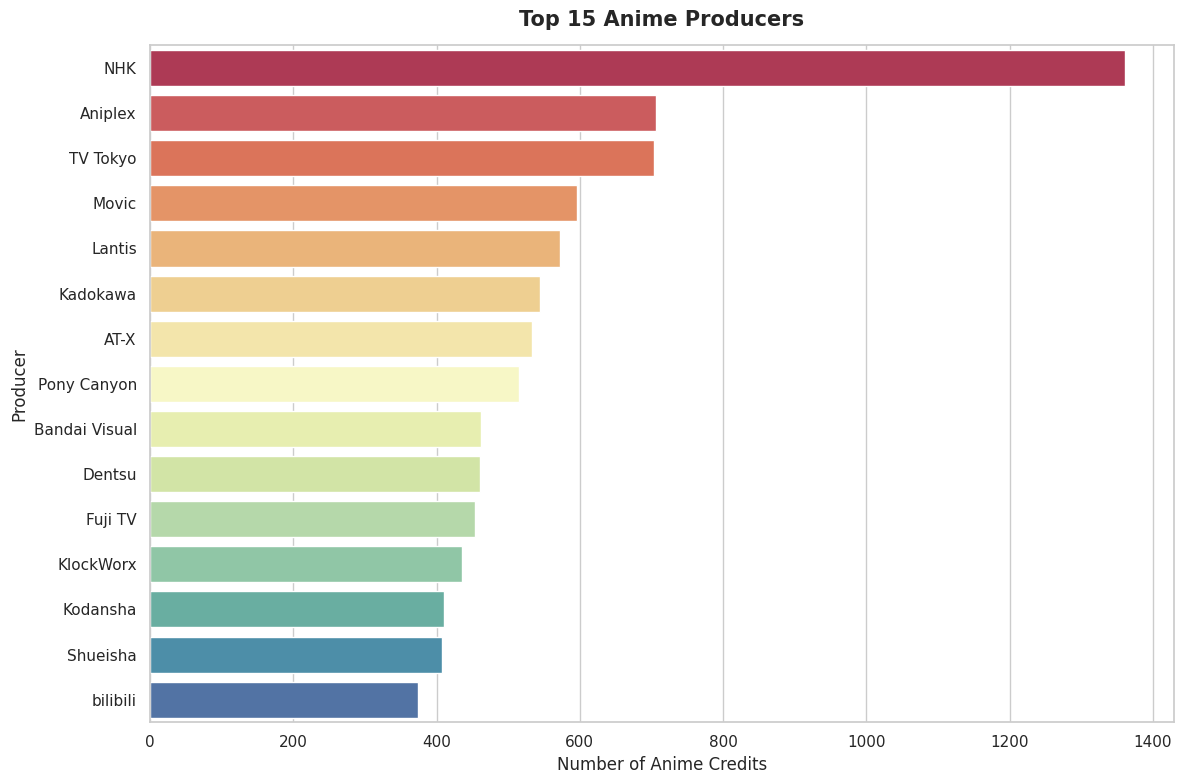

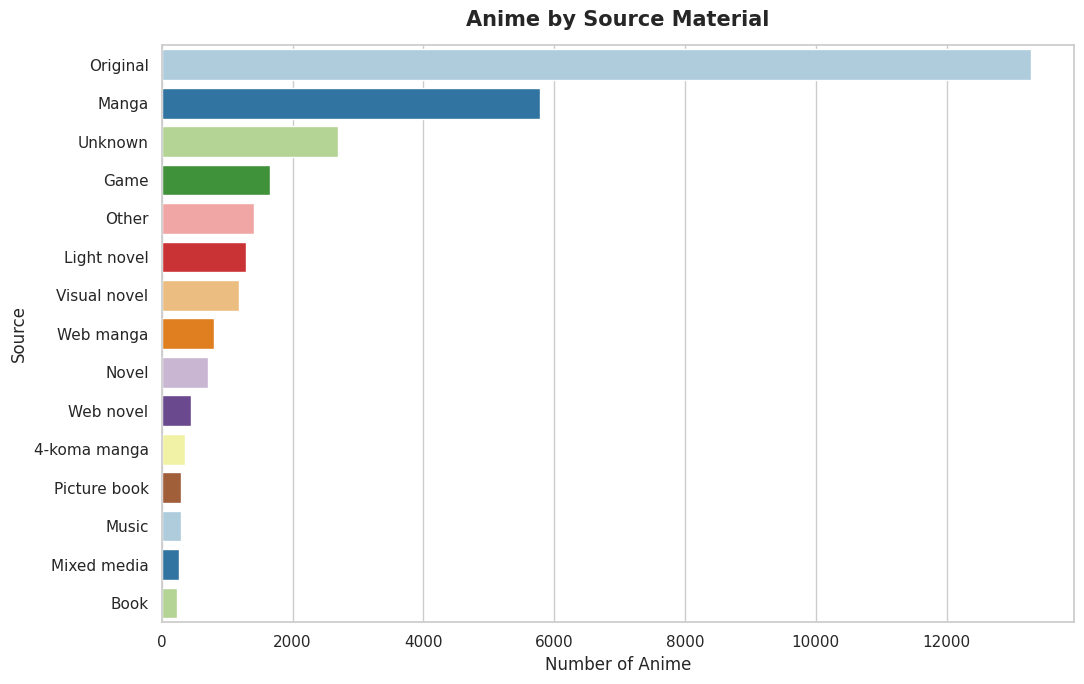

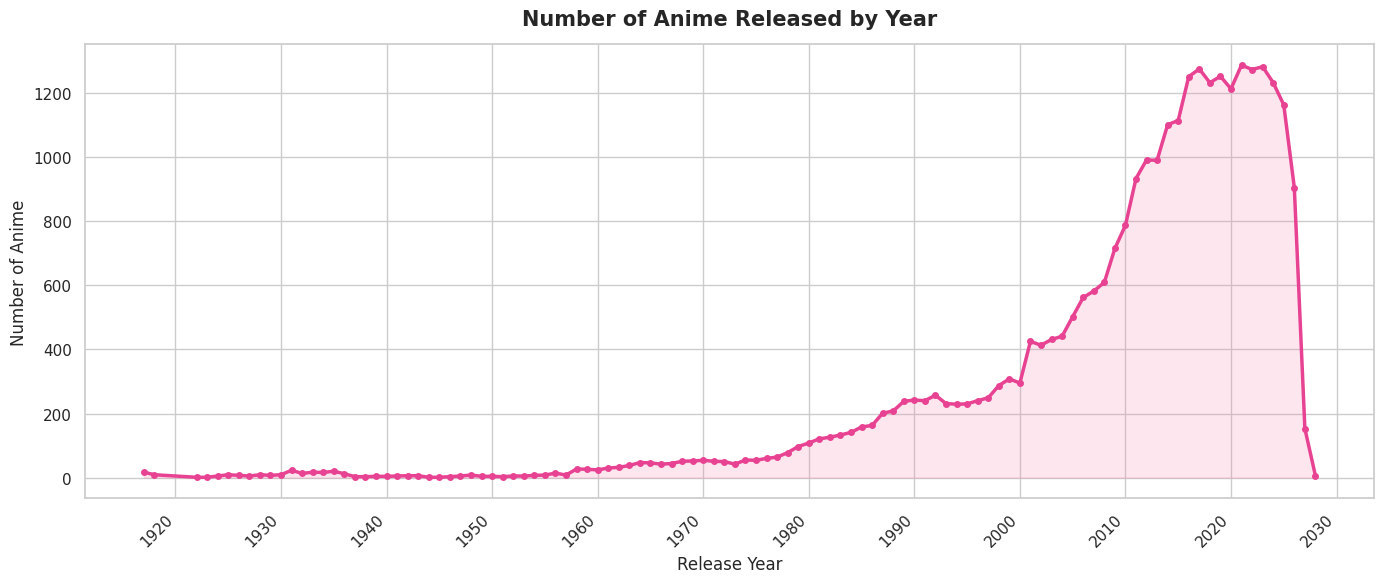

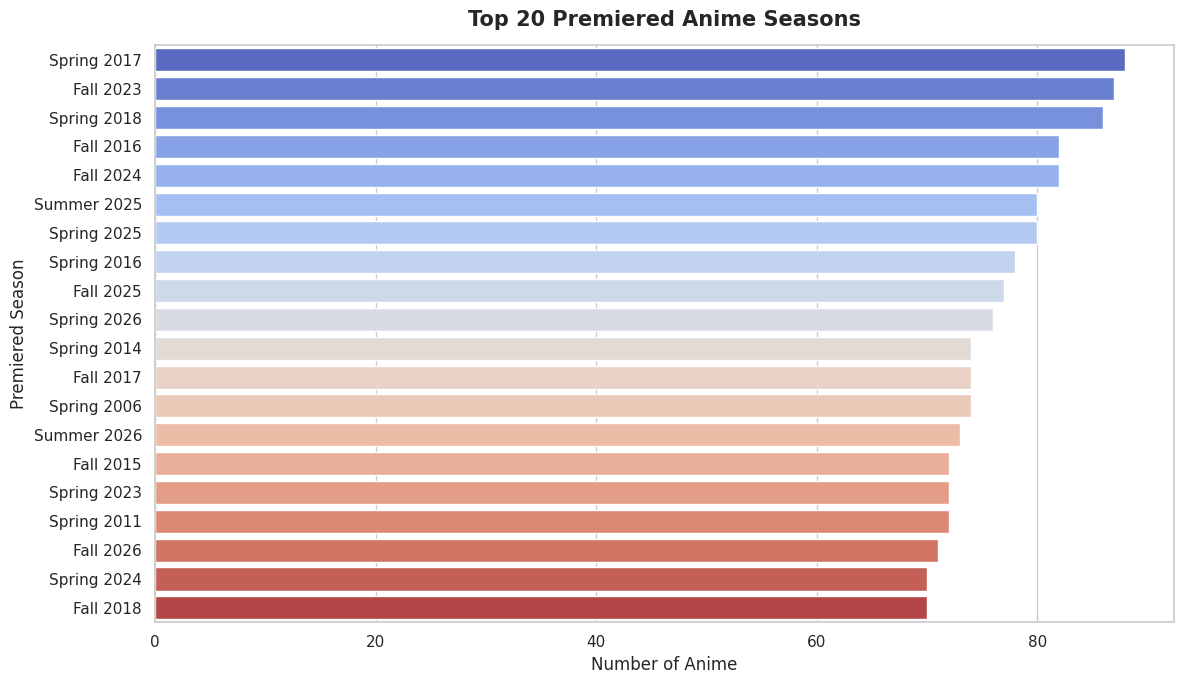

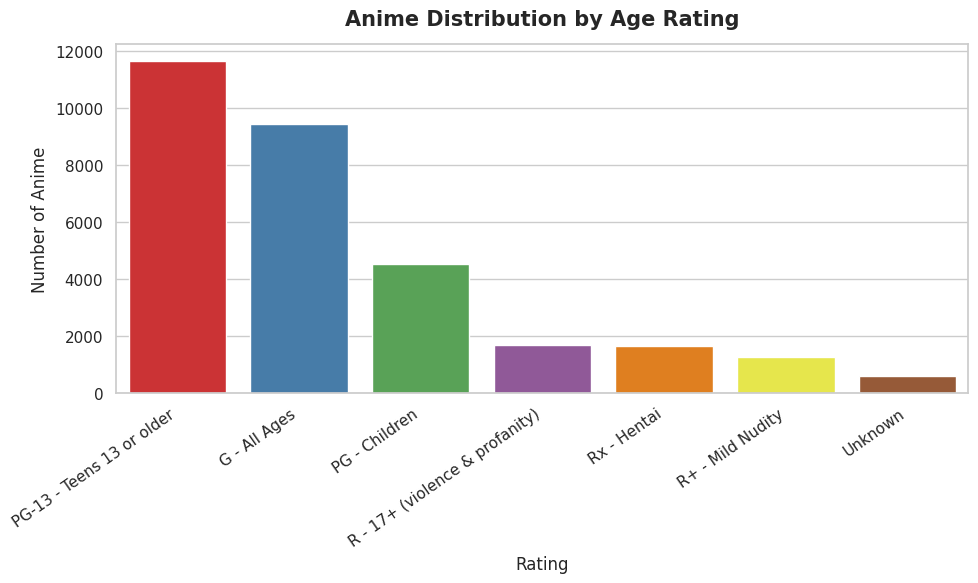

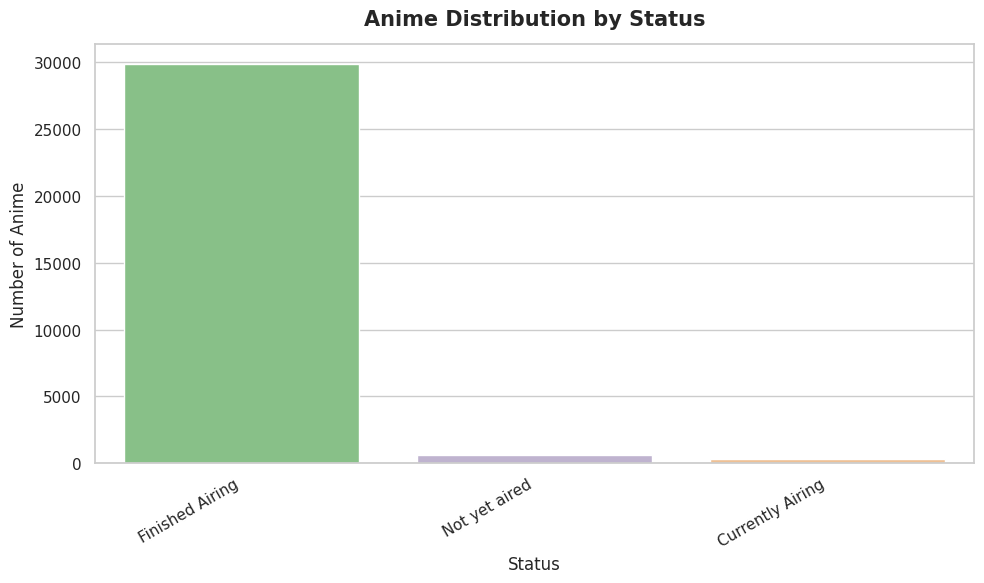

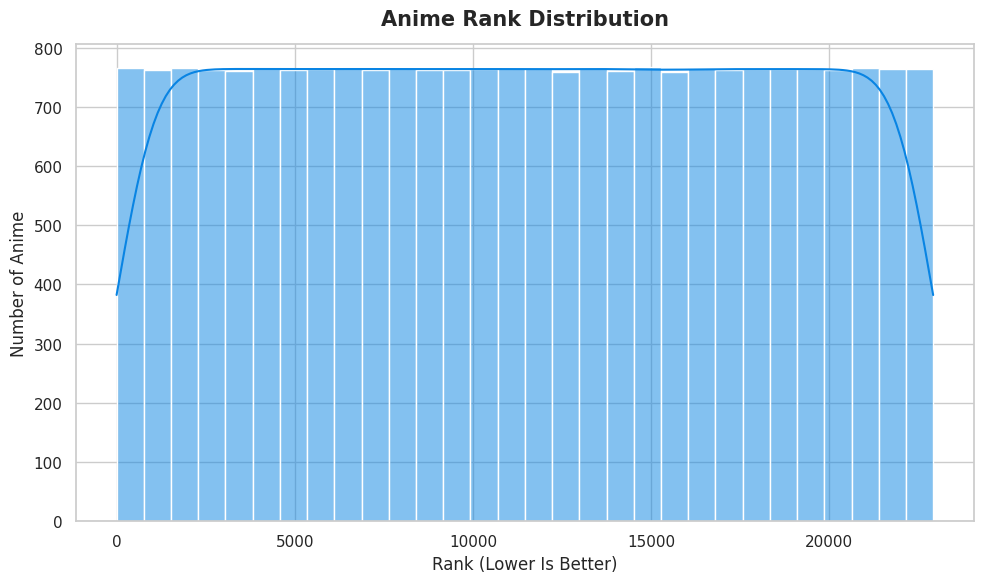

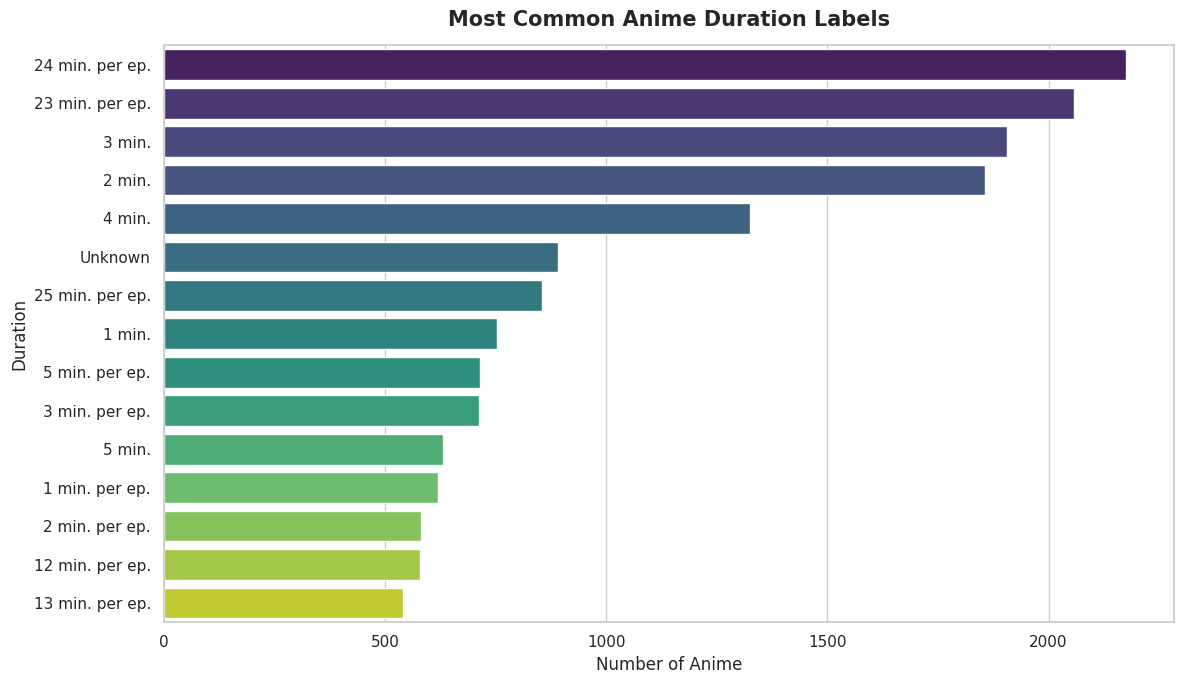

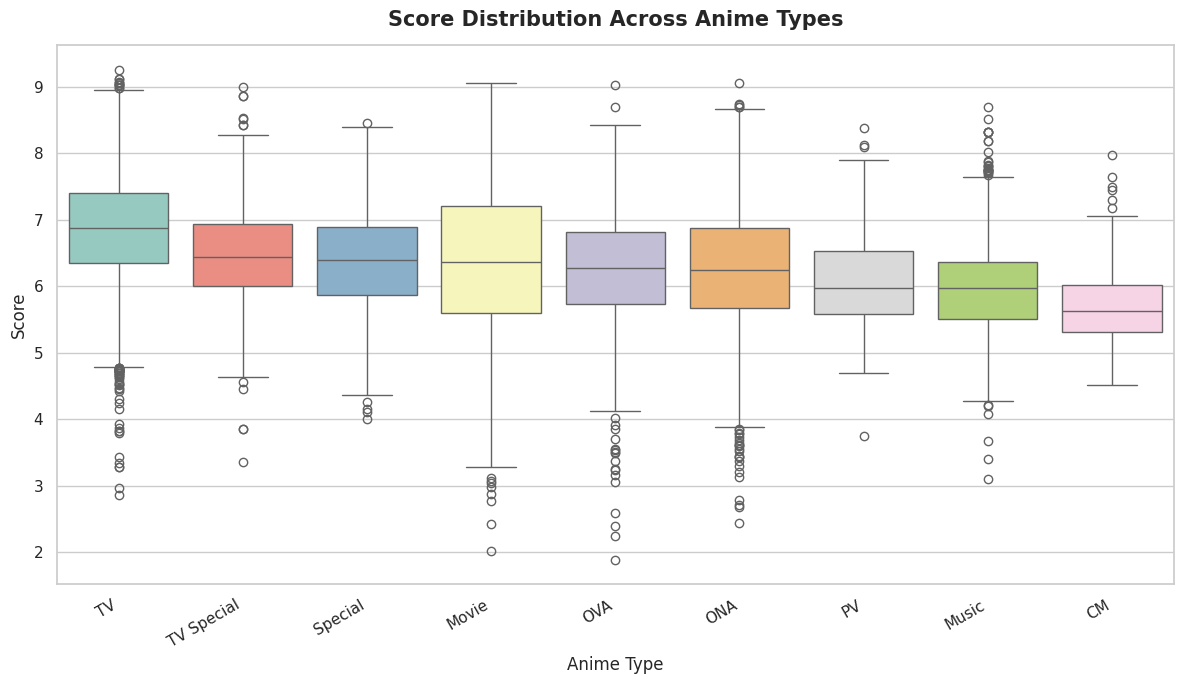

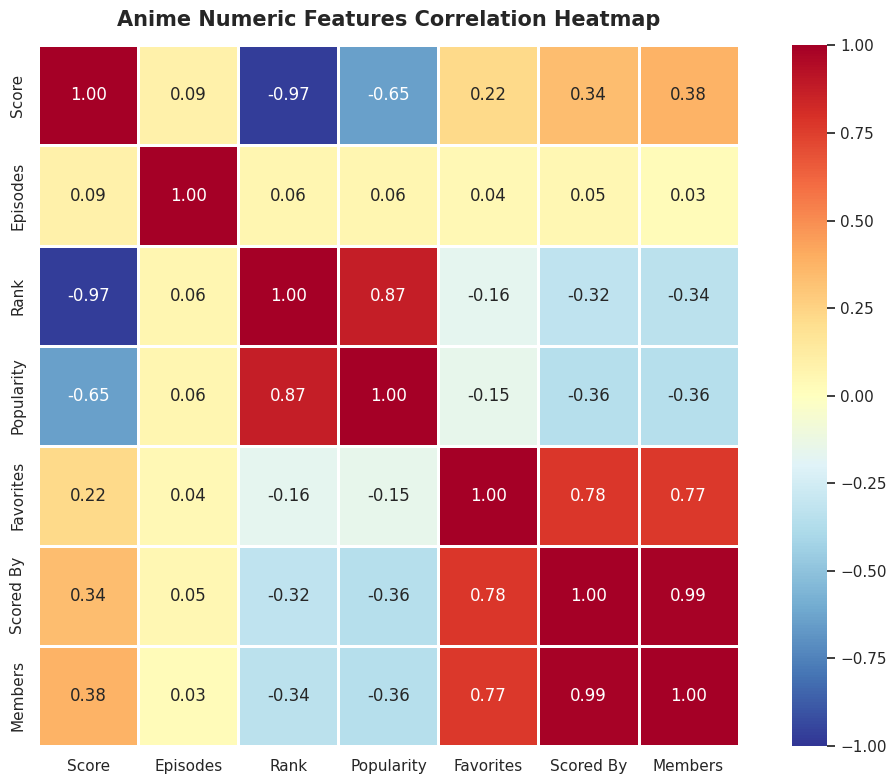

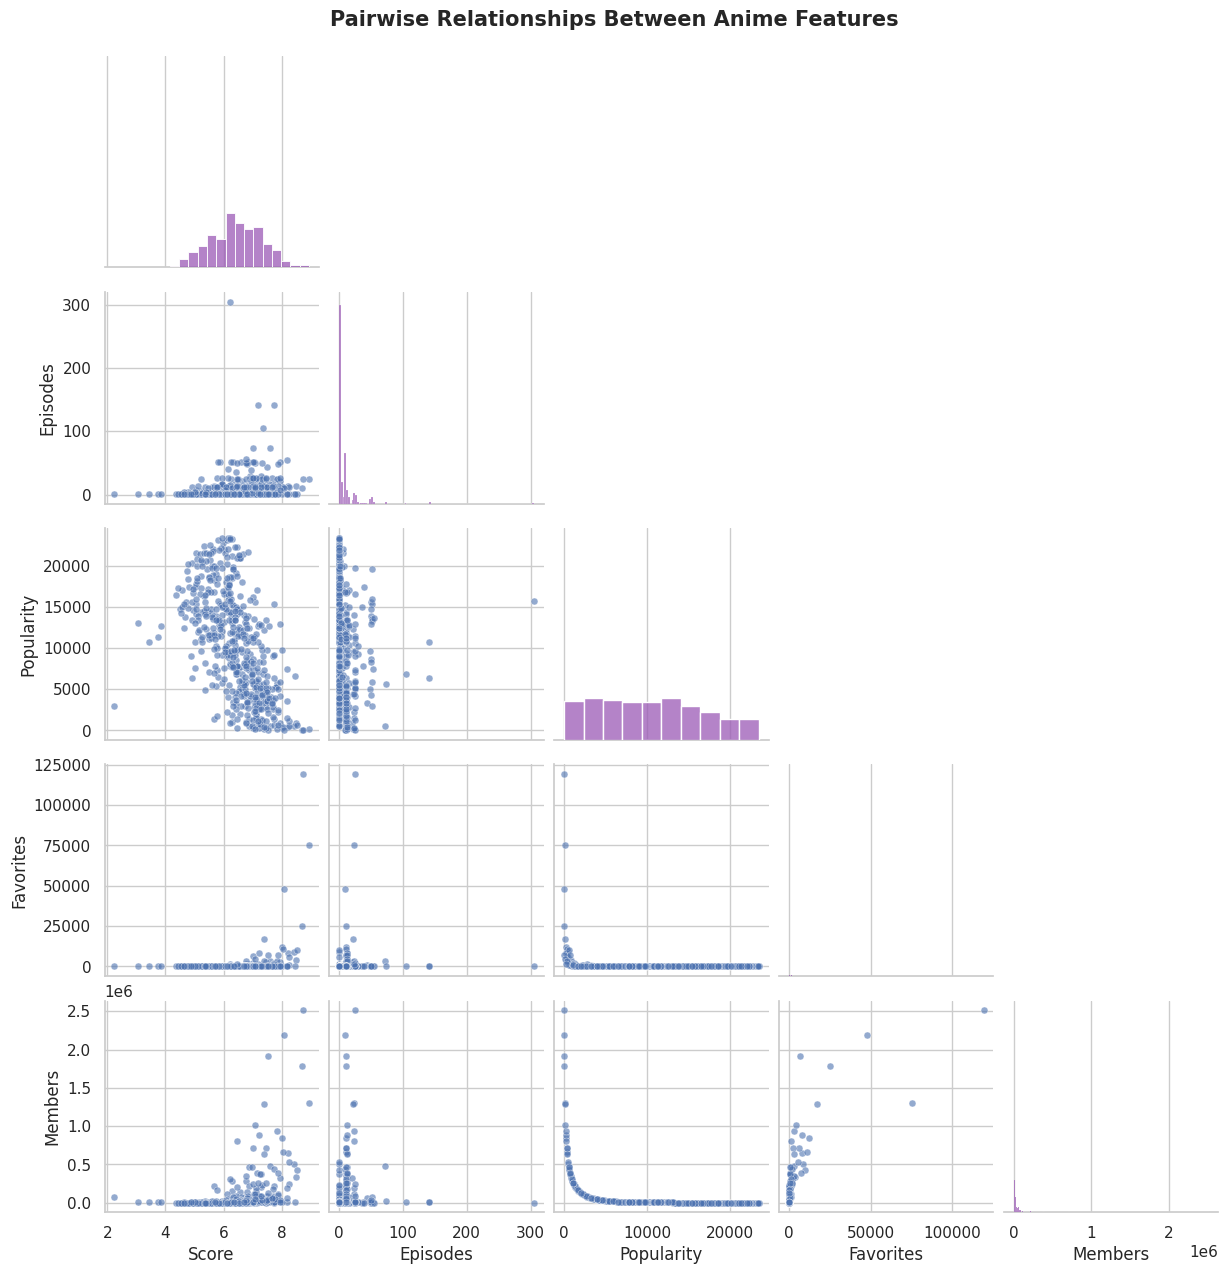

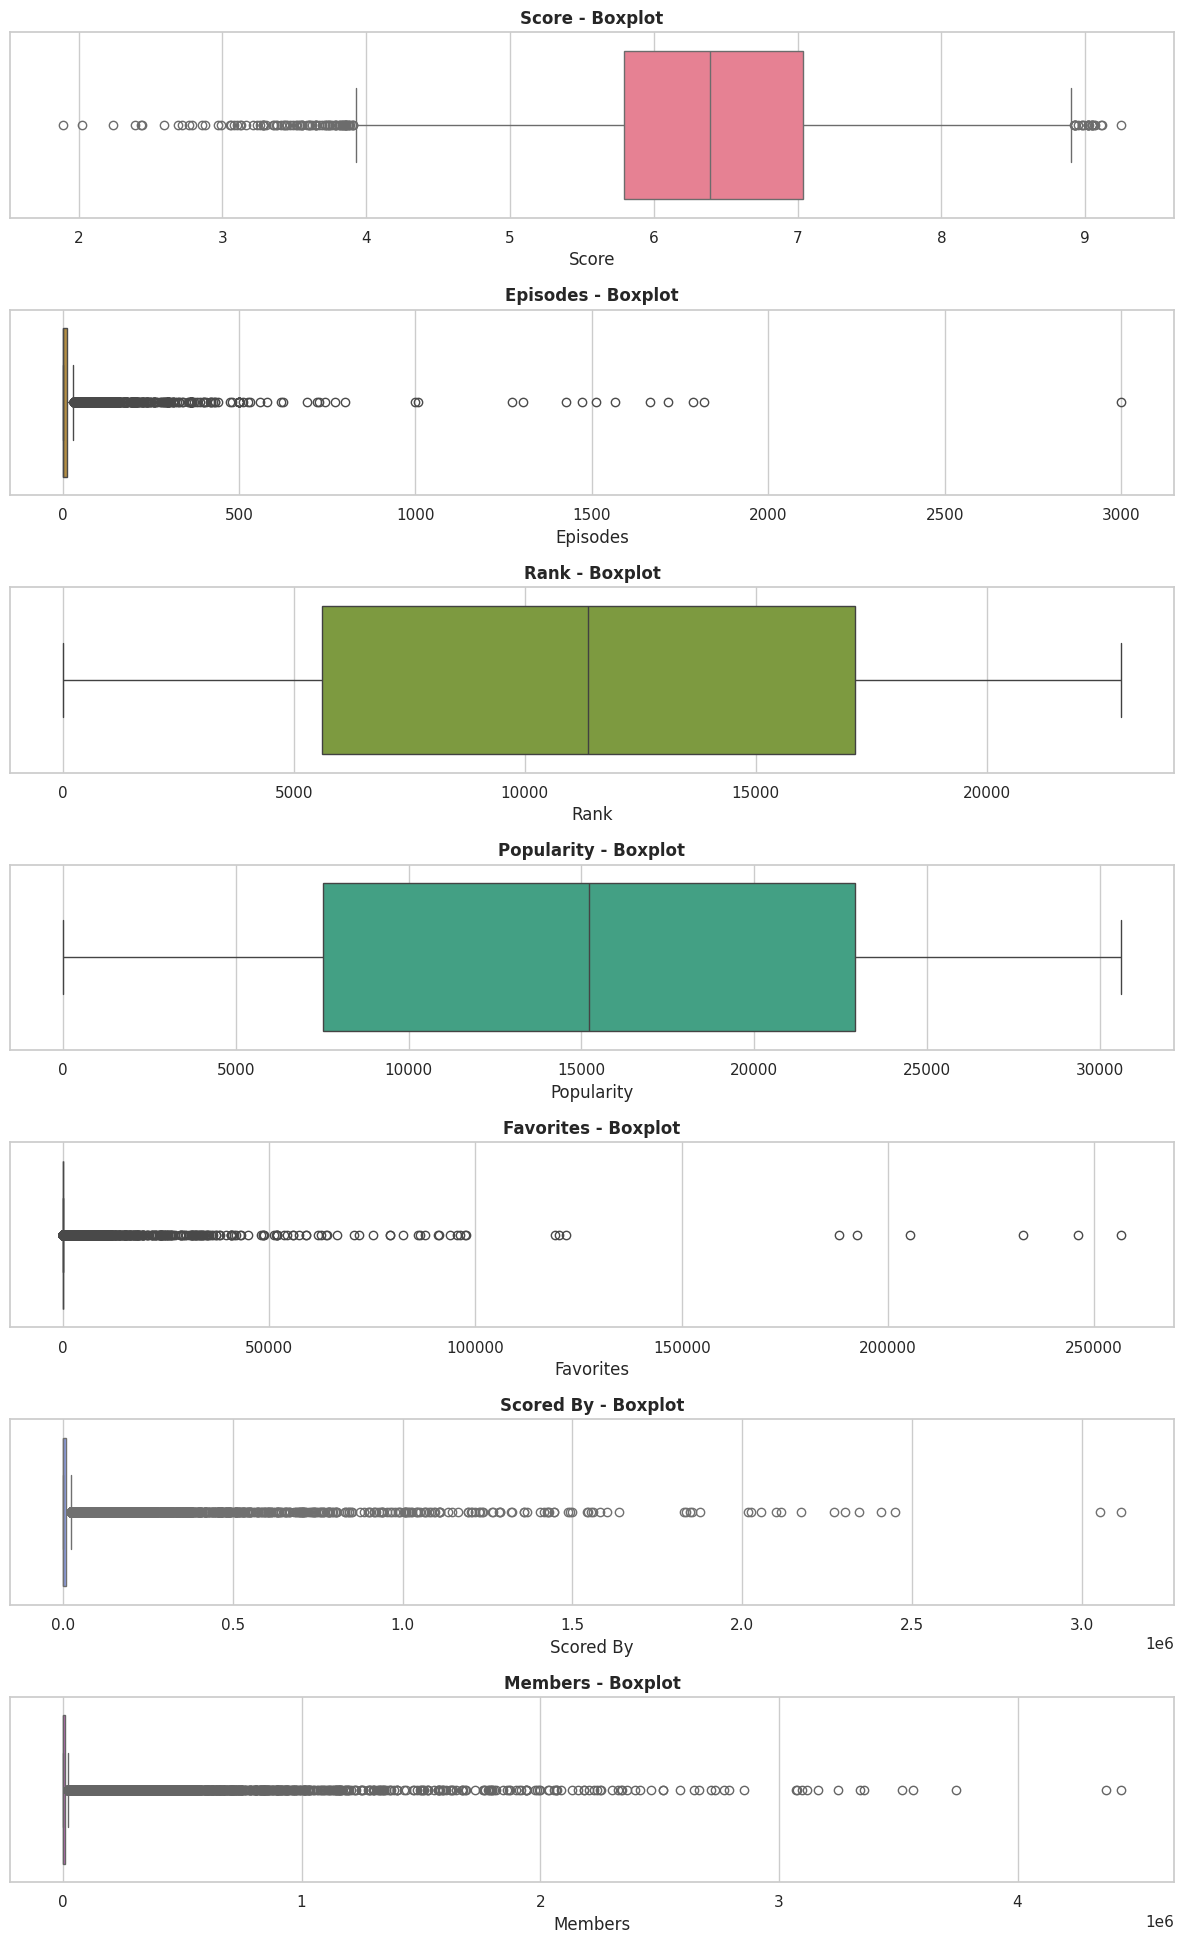


ANIME DATASET VISUALIZATION SUMMARY
Total anime records: 30763
Unique anime names: 30753

Anime type counts:


,Count
Type,
TV,8770
Movie,5092
Music,4631
ONA,4445
OVA,4273
Special,1771
TV Special,817
CM,523
PV,371



Score statistics:


,Score Statistics
count,20358.000000
mean,6.409782
std,0.886678
min,1.890000
25%,5.790000
50%,6.390000
75%,7.040000
max,9.250000



Most frequent genres:


,Anime Count
Genres,
Comedy,8042
Kids,7111
Fantasy,6321
Music,5809
Action,5047
Adventure,4635
Sci-Fi,3618
Drama,3194
School,2340



All available visualization sections have been processed.


In [13]:

# ================================================================
# COMPLETE ANIME DATASET VISUALIZATION
# Colorful charts | EDA | Ratings | Genres | Popularity | Studios
# ================================================================

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

from matplotlib.ticker import MaxNLocator

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

sns.set_theme(style="whitegrid", context="notebook")

# Use df if already loaded.
# Example:
# df = pd.read_csv("/content/anime.csv")

if "df" not in globals():
    raise NameError("Please load your anime dataset into a DataFrame named df.")

df = df.copy()

# Remove duplicate column names safely
df = df.loc[:, ~df.columns.duplicated()]

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Required columns
expected_columns = [
    "anime_id", "Name", "English name", "Other name", "Score",
    "Genres", "Synopsis", "Type", "Episodes", "Aired",
    "Premiered", "Status", "Producers", "Licensors", "Studios",
    "Source", "Duration", "Rating", "Rank", "Popularity",
    "Favorites", "Scored By", "Members", "Image URL"
]

missing_columns = [c for c in expected_columns if c not in df.columns]

if missing_columns:
    print("Columns not found:", missing_columns)

print("=" * 70)
print("ANIME DATASET OVERVIEW")
print("=" * 70)
print("Dataset shape:", df.shape)
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))
print("\nColumn names:\n", df.columns.tolist())
print("\nFirst 5 records:")
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values:")
display(
    df.isnull().sum()
      .sort_values(ascending=False)
      .to_frame("Missing Values")
      .query("`Missing Values` > 0")
)

print("\nDuplicate rows:", df.duplicated().sum())

# ------------------------------------------------
# 2. DATA CLEANING FOR VISUALIZATION
# ------------------------------------------------

# Convert numeric columns safely
numeric_columns = [
    "Score", "Episodes", "Rank", "Popularity",
    "Favorites", "Scored By", "Members"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Replace common missing-value text with NaN
missing_text = [
    "Unknown", "unknown", "UNKNOWN", "N/A",
    "n/a", "None", "none", "?"
]

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].replace(missing_text, np.nan)

# Score validity: common anime scores use a 0-10 scale.
# Remove invalid scores from score-specific plots only.
score_valid = df.loc[df["Score"].between(0, 10)].copy()

# Helper for readable titles
def plot_title(title):
    plt.title(title, fontsize=15, fontweight="bold", pad=14)

def finish_plot(rotation=0):
    plt.xticks(rotation=rotation, ha="right" if rotation else "center")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 3. MISSING VALUES VISUALIZATION
# ------------------------------------------------

missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if not missing.empty:
    plt.figure(figsize=(13, 6))
    colors = sns.color_palette("rocket", len(missing))
    plt.bar(missing.index, missing.values, color=colors)
    plot_title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    finish_plot(60)
else:
    print("No missing values found.")

# ------------------------------------------------
# 4. TOP ANIME BY SCORE
# ------------------------------------------------

if not score_valid.empty and "Name" in df.columns:
    top_score = (
        score_valid.dropna(subset=["Name", "Score"])
        .nlargest(15, "Score")
        .sort_values("Score")
    )

    plt.figure(figsize=(12, 8))
    colors = sns.color_palette("viridis", len(top_score))

    plt.barh(
        top_score["Name"].astype(str),
        top_score["Score"],
        color=colors,
        edgecolor="black",
        linewidth=0.4
    )

    plot_title("Top 15 Anime by Score")
    plt.xlabel("Score (0–10)")
    plt.ylabel("Anime")
    finish_plot()

# ------------------------------------------------
# 5. SCORE DISTRIBUTION
# ------------------------------------------------

if not score_valid.empty:
    plt.figure(figsize=(10, 6))

    sns.histplot(
        score_valid["Score"].dropna(),
        bins=25,
        kde=True,
        color="#6C5CE7",
        edgecolor="white"
    )

    plt.axvline(
        score_valid["Score"].mean(),
        color="#E17055",
        linestyle="--",
        linewidth=2,
        label=f'Mean: {score_valid["Score"].mean():.2f}'
    )

    plot_title("Anime Score Distribution")
    plt.xlabel("Score")
    plt.ylabel("Number of Anime")
    plt.legend()
    finish_plot()

# ------------------------------------------------
# 6. ANIME TYPE DISTRIBUTION
# ------------------------------------------------

if "Type" in df.columns:
    type_counts = df["Type"].fillna("Unknown").value_counts()

    plt.figure(figsize=(9, 7))
    colors = sns.color_palette("Set2", len(type_counts))

    plt.pie(
        type_counts.values,
        labels=type_counts.index,
        autopct="%1.1f%%",
        startangle=140,
        colors=colors,
        explode=[0.04] * len(type_counts),
        wedgeprops={"edgecolor": "white", "linewidth": 1.5}
    )

    plot_title("Anime Distribution by Type")
    plt.axis("equal")
    finish_plot()

# ------------------------------------------------
# 7. ANIME COUNTS BY TYPE
# ------------------------------------------------

if "Type" in df.columns:
    type_counts = df["Type"].fillna("Unknown").value_counts()

    plt.figure(figsize=(10, 6))
    sns.barplot(
        x=type_counts.index,
        y=type_counts.values,
        hue=type_counts.index,
        palette="Set2",
        legend=False
    )

    plot_title("Number of Anime by Type")
    plt.xlabel("Anime Type")
    plt.ylabel("Number of Anime")
    finish_plot(35)

# ------------------------------------------------
# 8. GENRE FREQUENCY
# ------------------------------------------------

if "Genres" in df.columns:
    genre_series = (
        df["Genres"].dropna().astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    genre_series = genre_series[
        (genre_series != "") &
        (genre_series.str.lower() != "unknown")
    ]

    genre_counts = genre_series.value_counts().head(20)

    if not genre_counts.empty:
        plt.figure(figsize=(12, 8))

        sns.barplot(
            x=genre_counts.values,
            y=genre_counts.index,
            hue=genre_counts.index,
            palette="Spectral",
            legend=False
        )

        plot_title("Top 20 Most Common Anime Genres")
        plt.xlabel("Number of Anime")
        plt.ylabel("Genre")
        finish_plot()

# ------------------------------------------------
# 9. GENRES WITH HIGHEST AVERAGE SCORE
# ------------------------------------------------

if {"Genres", "Score"}.issubset(df.columns):
    genre_score_df = df.dropna(subset=["Genres", "Score"]).copy()

    genre_score_df["Genre"] = genre_score_df["Genres"].astype(str).str.split(",")
    genre_score_df = genre_score_df.explode("Genre")
    genre_score_df["Genre"] = genre_score_df["Genre"].str.strip()

    genre_score_df = genre_score_df[
        (genre_score_df["Genre"] != "") &
        (genre_score_df["Genre"].str.lower() != "unknown") &
        genre_score_df["Score"].between(0, 10)
    ]

    genre_avg = (
        genre_score_df.groupby("Genre")["Score"]
        .agg(["mean", "count"])
        .query("count >= 5")
        .sort_values("mean", ascending=False)
        .head(15)
        .sort_values("mean")
    )

    if not genre_avg.empty:
        plt.figure(figsize=(12, 8))

        sns.barplot(
            x=genre_avg["mean"],
            y=genre_avg.index,
            hue=genre_avg.index,
            palette="magma",
            legend=False
        )

        plot_title("Top 15 Genres by Average Score (Minimum 5 Anime)")
        plt.xlabel("Average Score")
        plt.ylabel("Genre")
        finish_plot()

# ------------------------------------------------
# 10. EPISODES DISTRIBUTION
# ------------------------------------------------

if "Episodes" in df.columns:
    episodes = df.loc[
        df["Episodes"].between(1, 1000),
        "Episodes"
    ].dropna()

    if not episodes.empty:
        plt.figure(figsize=(11, 6))

        sns.histplot(
            episodes,
            bins=30,
            kde=True,
            color="#00B894",
            edgecolor="white"
        )

        plot_title("Anime Episodes Distribution")
        plt.xlabel("Number of Episodes")
        plt.ylabel("Number of Anime")
        finish_plot()

# ------------------------------------------------
# 11. TOP ANIME BY EPISODE COUNT
# ------------------------------------------------

if {"Name", "Episodes"}.issubset(df.columns):
    episode_top = (
        df.dropna(subset=["Name", "Episodes"])
        .nlargest(15, "Episodes")
        .sort_values("Episodes")
    )

    if not episode_top.empty:
        plt.figure(figsize=(12, 8))

        colors = sns.color_palette("coolwarm", len(episode_top))

        plt.barh(
            episode_top["Name"].astype(str),
            episode_top["Episodes"],
            color=colors
        )

        plot_title("Top 15 Anime by Episode Count")
        plt.xlabel("Episodes")
        plt.ylabel("Anime")
        finish_plot()

# ------------------------------------------------
# 12. SCORE VS POPULARITY
# ------------------------------------------------

if {"Score", "Popularity"}.issubset(df.columns):
    scatter_df = df[
        df["Score"].between(0, 10) &
        df["Popularity"].gt(0)
    ].dropna(subset=["Score", "Popularity"])

    if not scatter_df.empty:
        # Sample large datasets to keep the plot responsive
        scatter_df = scatter_df.sample(
            n=min(10000, len(scatter_df)),
            random_state=42
        )

        plt.figure(figsize=(11, 7))

        sns.scatterplot(
            data=scatter_df,
            x="Popularity",
            y="Score",
            hue="Score",
            palette="viridis",
            size="Members" if "Members" in scatter_df.columns
                 and scatter_df["Members"].notna().any() else None,
            sizes=(20, 150),
            alpha=0.7,
            legend="brief"
        )

        plot_title("Anime Score vs Popularity")
        plt.xlabel("Popularity Rank (Lower Number = More Popular)")
        plt.ylabel("Score")
        finish_plot()

# ------------------------------------------------
# 13. SCORE VS MEMBERS
# ------------------------------------------------

if {"Score", "Members"}.issubset(df.columns):
    members_df = df[
        df["Score"].between(0, 10) &
        df["Members"].gt(0)
    ].dropna(subset=["Score", "Members"])

    if not members_df.empty:
        members_df = members_df.sample(
            n=min(10000, len(members_df)),
            random_state=42
        )

        plt.figure(figsize=(11, 7))

        sns.scatterplot(
            data=members_df,
            x="Members",
            y="Score",
            hue="Score",
            palette="plasma",
            alpha=0.7
        )

        plt.xscale("log")
        plot_title("Anime Score vs Community Members")
        plt.xlabel("Members (Log Scale)")
        plt.ylabel("Score")
        finish_plot()

# ------------------------------------------------
# 14. TOP ANIME BY MEMBERS
# ------------------------------------------------

if {"Name", "Members"}.issubset(df.columns):
    top_members = (
        df.dropna(subset=["Name", "Members"])
        .nlargest(15, "Members")
        .sort_values("Members")
    )

    if not top_members.empty:
        plt.figure(figsize=(12, 8))

        plt.barh(
            top_members["Name"].astype(str),
            top_members["Members"],
            color=sns.color_palette("crest", len(top_members))
        )

        plot_title("Top 15 Anime by Number of Members")
        plt.xlabel("Members")
        plt.ylabel("Anime")
        finish_plot()

# ------------------------------------------------
# 15. TOP ANIME BY FAVORITES
# ------------------------------------------------

if {"Name", "Favorites"}.issubset(df.columns):
    top_favorites = (
        df.dropna(subset=["Name", "Favorites"])
        .nlargest(15, "Favorites")
        .sort_values("Favorites")
    )

    if not top_favorites.empty:
        plt.figure(figsize=(12, 8))

        plt.barh(
            top_favorites["Name"].astype(str),
            top_favorites["Favorites"],
            color=sns.color_palette("flare", len(top_favorites))
        )

        plot_title("Top 15 Anime by Favorites")
        plt.xlabel("Favorites")
        plt.ylabel("Anime")
        finish_plot()

# ------------------------------------------------
# 16. TOP ANIME BY NUMBER OF SCORERS
# ------------------------------------------------

if {"Name", "Scored By"}.issubset(df.columns):
    top_scorers = (
        df.dropna(subset=["Name", "Scored By"])
        .nlargest(15, "Scored By")
        .sort_values("Scored By")
    )

    if not top_scorers.empty:
        plt.figure(figsize=(12, 8))

        plt.barh(
            top_scorers["Name"].astype(str),
            top_scorers["Scored By"],
            color=sns.color_palette("rocket", len(top_scorers))
        )

        plot_title("Top 15 Anime by Number of Scorers")
        plt.xlabel("Number of Scorers")
        plt.ylabel("Anime")
        finish_plot()

# ------------------------------------------------
# 17. STUDIOS PRODUCING THE MOST ANIME
# ------------------------------------------------

if "Studios" in df.columns:
    studio_series = (
        df["Studios"].dropna().astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    studio_series = studio_series[
        (studio_series != "") &
        (studio_series.str.lower() != "unknown")
    ]

    studio_counts = studio_series.value_counts().head(15)

    if not studio_counts.empty:
        plt.figure(figsize=(12, 8))

        sns.barplot(
            x=studio_counts.values,
            y=studio_counts.index,
            hue=studio_counts.index,
            palette="husl",
            legend=False
        )

        plot_title("Top 15 Anime Studios")
        plt.xlabel("Number of Anime Credits")
        plt.ylabel("Studio")
        finish_plot()

# ------------------------------------------------
# 18. TOP PRODUCERS
# ------------------------------------------------

if "Producers" in df.columns:
    producer_series = (
        df["Producers"].dropna().astype(str)
        .str.split(",")
        .explode()
        .str.strip()
    )

    producer_series = producer_series[
        (producer_series != "") &
        (producer_series.str.lower() != "unknown")
    ]

    producer_counts = producer_series.value_counts().head(15)

    if not producer_counts.empty:
        plt.figure(figsize=(12, 8))

        sns.barplot(
            x=producer_counts.values,
            y=producer_counts.index,
            hue=producer_counts.index,
            palette="Spectral",
            legend=False
        )

        plot_title("Top 15 Anime Producers")
        plt.xlabel("Number of Anime Credits")
        plt.ylabel("Producer")
        finish_plot()

# ------------------------------------------------
# 19. SOURCE MATERIAL DISTRIBUTION
# ------------------------------------------------

if "Source" in df.columns:
    source_counts = df["Source"].fillna("Unknown").value_counts().head(15)

    plt.figure(figsize=(11, 7))

    sns.barplot(
        x=source_counts.values,
        y=source_counts.index,
        hue=source_counts.index,
        palette="Paired",
        legend=False
    )

    plot_title("Anime by Source Material")
    plt.xlabel("Number of Anime")
    plt.ylabel("Source")
    finish_plot()

# ------------------------------------------------
# 20. ANIME AGE / RELEASE YEAR ANALYSIS
# ------------------------------------------------

if "Aired" in df.columns:
    # Extract years such as 1998 from date ranges
    df["Release_Year"] = pd.to_numeric(
        df["Aired"].astype("string").str.extract(r"((?:19|20)\d{2})")[0],
        errors="coerce"
    )

    yearly_counts = (
        df["Release_Year"].dropna()
        .astype(int)
        .value_counts()
        .sort_index()
    )

    # Exclude extreme years outside common anime history
    yearly_counts = yearly_counts[
        (yearly_counts.index >= 1900) &
        (yearly_counts.index <= 2030)
    ]

    if not yearly_counts.empty:
        plt.figure(figsize=(14, 6))

        plt.plot(
            yearly_counts.index,
            yearly_counts.values,
            color="#E84393",
            linewidth=2.5,
            marker="o",
            markersize=4
        )

        plt.fill_between(
            yearly_counts.index,
            yearly_counts.values,
            alpha=0.18,
            color="#FD79A8"
        )

        plot_title("Number of Anime Released by Year")
        plt.xlabel("Release Year")
        plt.ylabel("Number of Anime")
        plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True, nbins=15))
        finish_plot(45)

# ------------------------------------------------
# 21. PREMIERED SEASON DISTRIBUTION
# ------------------------------------------------

if "Premiered" in df.columns:
    premiered = df["Premiered"].dropna().astype(str)

    season_counts = premiered.value_counts().head(20)

    if not season_counts.empty:
        plt.figure(figsize=(12, 7))

        sns.barplot(
            x=season_counts.values,
            y=season_counts.index,
            hue=season_counts.index,
            palette="coolwarm",
            legend=False
        )

        plot_title("Top 20 Premiered Anime Seasons")
        plt.xlabel("Number of Anime")
        plt.ylabel("Premiered Season")
        finish_plot()

# ------------------------------------------------
# 22. AGE RATING DISTRIBUTION
# ------------------------------------------------

if "Rating" in df.columns:
    rating_counts = df["Rating"].fillna("Unknown").value_counts()

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=rating_counts.index,
        y=rating_counts.values,
        hue=rating_counts.index,
        palette="Set1",
        legend=False
    )

    plot_title("Anime Distribution by Age Rating")
    plt.xlabel("Rating")
    plt.ylabel("Number of Anime")
    finish_plot(35)

# ------------------------------------------------
# 23. ANIME STATUS DISTRIBUTION
# ------------------------------------------------

if "Status" in df.columns:
    status_counts = df["Status"].fillna("Unknown").value_counts()

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=status_counts.index,
        y=status_counts.values,
        hue=status_counts.index,
        palette="Accent",
        legend=False
    )

    plot_title("Anime Distribution by Status")
    plt.xlabel("Status")
    plt.ylabel("Number of Anime")
    finish_plot(30)

# ------------------------------------------------
# 24. RANK DISTRIBUTION
# ------------------------------------------------

if "Rank" in df.columns:
    rank_values = df.loc[df["Rank"].gt(0), "Rank"].dropna()

    if not rank_values.empty:
        plt.figure(figsize=(10, 6))

        sns.histplot(
            rank_values,
            bins=30,
            color="#0984E3",
            kde=True
        )

        plot_title("Anime Rank Distribution")
        plt.xlabel("Rank (Lower Is Better)")
        plt.ylabel("Number of Anime")
        finish_plot()

# ------------------------------------------------
# 25. DURATION DISTRIBUTION
# ------------------------------------------------

if "Duration" in df.columns:
    duration_counts = (
        df["Duration"].fillna("Unknown")
        .value_counts()
        .head(15)
    )

    plt.figure(figsize=(12, 7))

    sns.barplot(
        x=duration_counts.values,
        y=duration_counts.index,
        hue=duration_counts.index,
        palette="viridis",
        legend=False
    )

    plot_title("Most Common Anime Duration Labels")
    plt.xlabel("Number of Anime")
    plt.ylabel("Duration")
    finish_plot()

# ------------------------------------------------
# 26. SCORE BOXPLOT BY ANIME TYPE
# ------------------------------------------------

if {"Type", "Score"}.issubset(df.columns):
    box_df = df[df["Score"].between(0, 10)].dropna(
        subset=["Type", "Score"]
    )

    if not box_df.empty:
        type_order = (
            box_df.groupby("Type")["Score"]
            .median()
            .sort_values(ascending=False)
            .index
        )

        plt.figure(figsize=(12, 7))

        sns.boxplot(
            data=box_df,
            x="Type",
            y="Score",
            order=type_order,
            hue="Type",
            palette="Set3",
            legend=False
        )

        plot_title("Score Distribution Across Anime Types")
        plt.xlabel("Anime Type")
        plt.ylabel("Score")
        finish_plot(30)

# ------------------------------------------------
# 27. CORRELATION HEATMAP
# ------------------------------------------------

correlation_columns = [
    c for c in [
        "Score", "Episodes", "Rank", "Popularity",
        "Favorites", "Scored By", "Members"
    ]
    if c in df.columns and pd.api.types.is_numeric_dtype(df[c])
]

if len(correlation_columns) >= 2:
    corr = df[correlation_columns].corr()

    plt.figure(figsize=(11, 8))

    sns.heatmap(
        corr,
        annot=True,
        cmap="RdYlBu_r",
        fmt=".2f",
        linewidths=0.8,
        square=True,
        vmin=-1,
        vmax=1,
        center=0
    )

    plot_title("Anime Numeric Features Correlation Heatmap")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 28. PAIRPLOT FOR NUMERIC FEATURES
# ------------------------------------------------

pair_columns = [
    c for c in [
        "Score", "Episodes", "Popularity",
        "Favorites", "Members"
    ]
    if c in df.columns
]

if len(pair_columns) >= 2:
    pair_df = df[pair_columns].replace([np.inf, -np.inf], np.nan).dropna()

    if not pair_df.empty:
        pair_df = pair_df.sample(
            n=min(500, len(pair_df)),
            random_state=42
        )

        sns.pairplot(
            pair_df,
            diag_kind="hist",
            corner=True,
            plot_kws={"alpha": 0.6, "s": 25},
            diag_kws={"color": "#9B59B6"}
        )

        plt.suptitle(
            "Pairwise Relationships Between Anime Features",
            y=1.02,
            fontsize=15,
            fontweight="bold"
        )
        plt.show()

# ------------------------------------------------
# 29. NUMERIC FEATURE BOXPLOTS
# ------------------------------------------------

box_columns = [
    c for c in [
        "Score", "Episodes", "Rank", "Popularity",
        "Favorites", "Scored By", "Members"
    ]
    if c in df.columns
]

if box_columns:
    fig, axes = plt.subplots(
        nrows=len(box_columns),
        ncols=1,
        figsize=(12, max(4, 2.8 * len(box_columns)))
    )

    axes = np.atleast_1d(axes)
    colors = sns.color_palette("husl", len(box_columns))

    for ax, col, color in zip(axes, box_columns, colors):
        values = df[col].replace([np.inf, -np.inf], np.nan).dropna()

        if col == "Score":
            values = values[values.between(0, 10)]

        if not values.empty:
            sns.boxplot(
                x=values,
                ax=ax,
                color=color
            )
            ax.set_title(f"{col} - Boxplot", fontweight="bold")
            ax.set_xlabel(col)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 30. FINAL SUMMARY
# ------------------------------------------------

print("\n" + "=" * 70)
print("ANIME DATASET VISUALIZATION SUMMARY")
print("=" * 70)

print("Total anime records:", len(df))

if "Name" in df.columns:
    print("Unique anime names:", df["Name"].nunique())

if "Type" in df.columns:
    print("\nAnime type counts:")
    display(df["Type"].value_counts(dropna=False).to_frame("Count"))

if not score_valid.empty:
    print("\nScore statistics:")
    display(score_valid["Score"].describe().to_frame("Score Statistics"))

if "Genres" in df.columns:
    print("\nMost frequent genres:")
    display(
        genre_series.value_counts().head(10).to_frame("Anime Count")
        if "genre_series" in globals()
        else pd.DataFrame()
    )

print("\nAll available visualization sections have been processed.")


## Feature engineering

Dataset shape: (20358, 26)

Target distribution:
Target
0    19572
1      786
Name: count, dtype: int64

Training data: (16286, 15)
Testing data: (4072, 15)

Numeric columns: ['Episodes', 'Rank', 'Popularity', 'Favorites', 'Scored By', 'Members', 'Release_Year']
Categorical columns: ['Genres', 'Type', 'Status', 'Producers', 'Licensors', 'Studios', 'Source', 'Rating']

Training: Logistic Regression
Model        Logistic Regression
Accuracy                0.929273
Precision               0.352144
Recall                  0.993631
F1 Score                    0.52
ROC-AUC                 0.992689

Classification report:
                precision    recall  f1-score   support

Not High-rated       1.00      0.93      0.96      3915
    High-rated       0.35      0.99      0.52       157

      accuracy                           0.93      4072
     macro avg       0.68      0.96      0.74      4072
  weighted avg       0.97      0.93      0.94      4072


Training: Decision Tree
Model        

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Random Forest,0.9998,1.0000,0.9936,0.9968,1.0000
1,Gradient Boosting,0.9998,1.0000,0.9936,0.9968,1.0000
2,Decision Tree,0.9975,0.9401,1.0000,0.9691,0.9997
3,Extra Trees,0.9858,0.7565,0.9299,0.8343,0.9982
4,Logistic Regression,0.9293,0.3521,0.9936,0.5200,0.9927
5,SVM,0.4904,0.0672,0.9490,0.1256,0.7657
6,KNN,0.9393,0.2750,0.3503,0.3081,0.7429


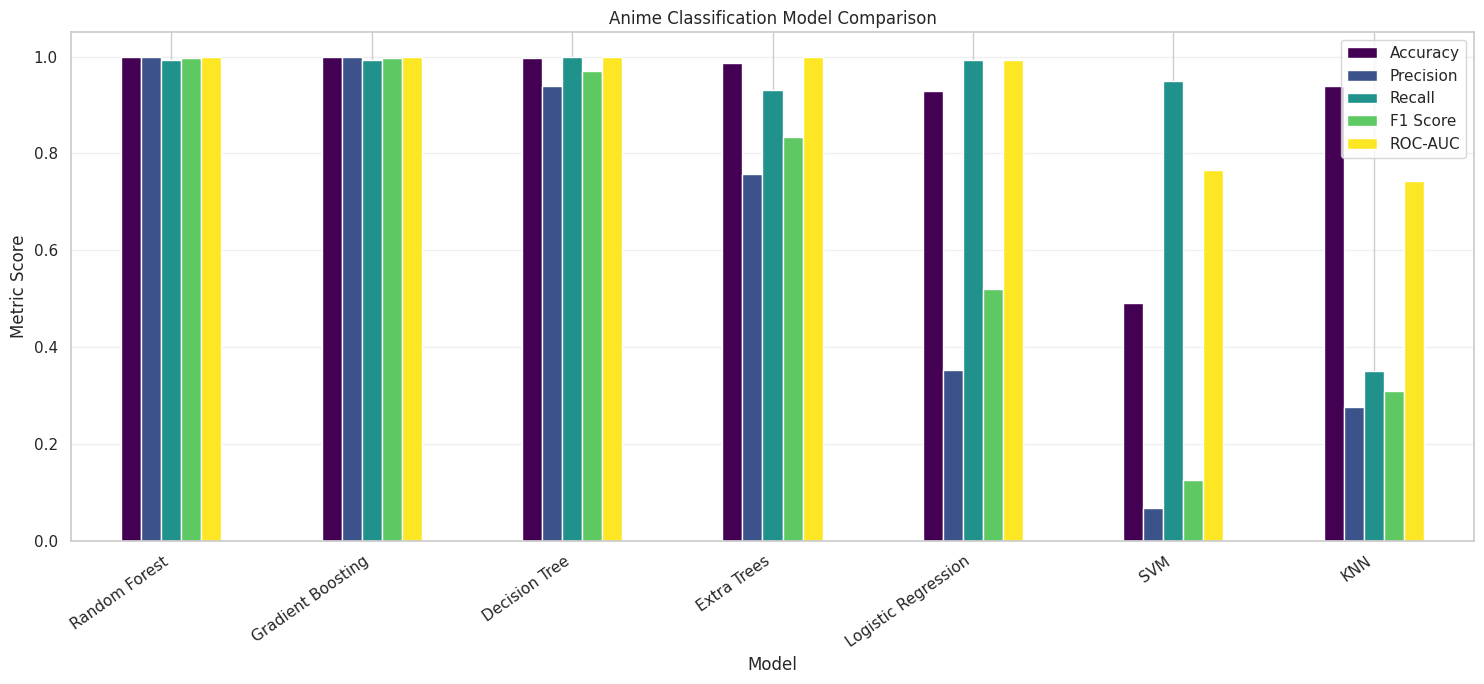

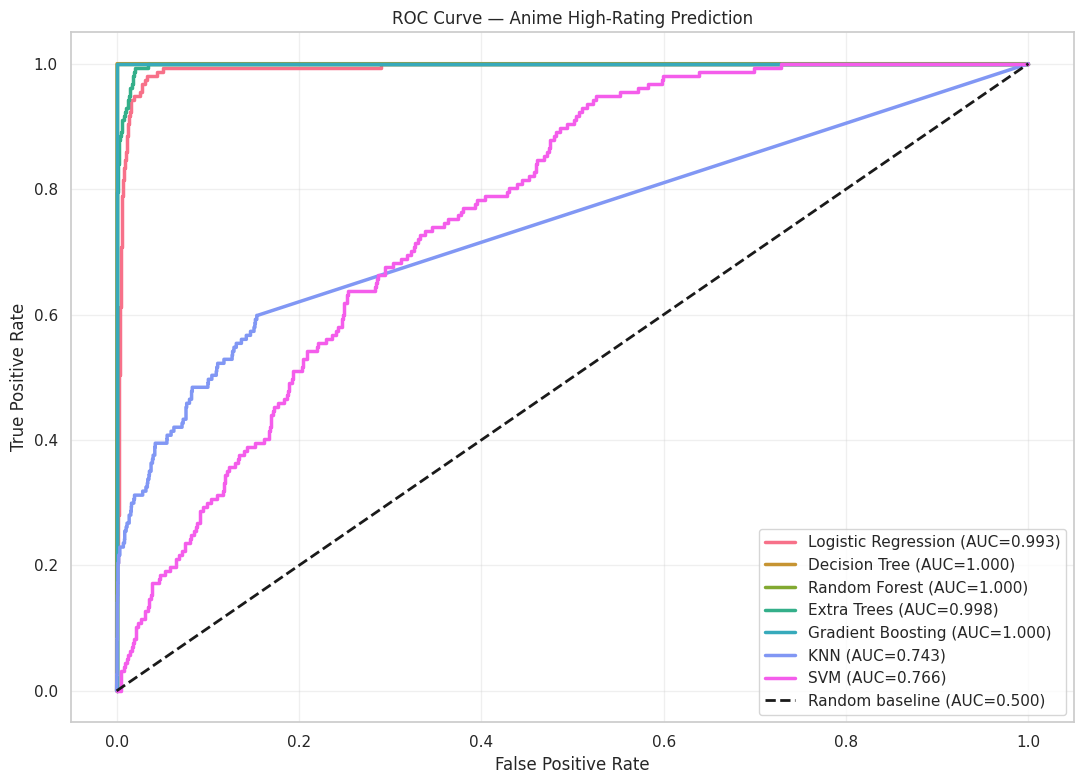


BEST MODEL: Random Forest
ROC-AUC: 1.0


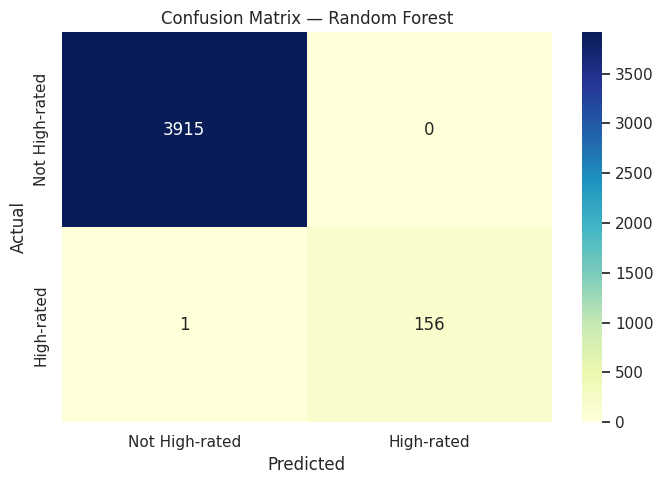


Best model report:
                precision    recall  f1-score   support

Not High-rated       1.00      1.00      1.00      3915
    High-rated       1.00      0.99      1.00       157

      accuracy                           1.00      4072
     macro avg       1.00      1.00      1.00      4072
  weighted avg       1.00      1.00      1.00      4072



In [14]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)

# ------------------------------------------------------------
# 1. PREPARE DATA
# ------------------------------------------------------------

if "df" not in globals():
    raise NameError("Load your anime dataset into df first.")

data = df.copy()
data = data.loc[:, ~data.columns.duplicated()]
data.columns = data.columns.str.strip()

if "Score" not in data.columns:
    raise ValueError("The Score column is missing.")

data["Score"] = pd.to_numeric(data["Score"], errors="coerce")
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(subset=["Score"])
data = data[data["Score"].between(0, 10)].copy()

# Binary classification target
data["Target"] = (data["Score"] >= 8.0).astype(int)

if data["Target"].nunique() != 2:
    raise ValueError(
        "Both target classes are required. Check the Score distribution."
    )

print("Dataset shape:", data.shape)
print("\nTarget distribution:")
print(data["Target"].value_counts())

# ------------------------------------------------------------
# 2. SELECT FEATURES AND AVOID DIRECT TARGET LEAKAGE
# ------------------------------------------------------------

exclude = [
    "Score", "Target", "anime_id",
    "Name", "English name", "Other name",
    "Synopsis", "Image URL", "Aired",
    "Premiered", "Duration"
]

X = data.drop(columns=exclude, errors="ignore").copy()
y = data["Target"].copy()

# Normalize columns: numeric where possible, otherwise text.
for col in X.columns:
    if pd.api.types.is_bool_dtype(X[col]):
        X[col] = X[col].astype(float)

    elif pd.api.types.is_numeric_dtype(X[col]):
        X[col] = pd.to_numeric(X[col], errors="coerce")

    else:
        # Try numeric conversion only if most nonmissing values
        # are actually numeric.
        original = X[col]
        converted = pd.to_numeric(original, errors="coerce")
        count = original.notna().sum()

        if count > 0 and converted.notna().sum() / count >= 0.90:
            X[col] = converted
        else:
            # Convert all categories to consistent plain strings.
            X[col] = original.astype(object)
            mask = original.notna()
            X.loc[mask, col] = original.loc[mask].astype(str)
            X.loc[~mask, col] = np.nan

# Remove completely empty columns
X = X.dropna(axis=1, how="all")

# Remove constant columns
constant_columns = [
    c for c in X.columns if X[c].nunique(dropna=True) <= 1
]
X = X.drop(columns=constant_columns)

if X.shape[1] == 0:
    raise ValueError("No usable feature columns remain.")

# ------------------------------------------------------------
# 3. TRAIN-TEST SPLIT BEFORE LEARNING ENCODINGS
# ------------------------------------------------------------

if y.value_counts().min() < 2:
    raise ValueError("Each target class needs at least 2 rows.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining data:", X_train.shape)
print("Testing data:", X_test.shape)

# ------------------------------------------------------------
# 4. PREPROCESSING AND CATEGORICAL LABEL ENCODING
# ------------------------------------------------------------

numeric_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_cols = [
    c for c in X_train.columns if c not in numeric_cols
]

print("\nNumeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

transformers = []

if numeric_cols:
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    transformers.append(
        ("numeric", numeric_pipe, numeric_cols)
    )

if categorical_cols:
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="__MISSING__"
        )),
        ("encoder", OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        ))
    ])

    transformers.append(
        ("categorical", categorical_pipe, categorical_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop",
    sparse_threshold=0
)

# ------------------------------------------------------------
# 5. DEFINE MODELS
# ------------------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=12,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100,
        max_depth=15,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.08,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5,
        weights="distance",
        n_jobs=-1
    ),

    "SVM": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    )
}

# ------------------------------------------------------------
# 6. TRAIN AND EVALUATE WITH REAL ERROR DIAGNOSTICS
# ------------------------------------------------------------

results = []
trained_models = {}
predictions = {}
probabilities = {}
failed_models = {}

for name, model in models.items():
    print("\n" + "=" * 60)
    print("Training:", name)

    try:
        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("classifier", model)
        ])

        pipeline.fit(X_train, y_train)

        pred = pipeline.predict(X_test)
        prob = pipeline.predict_proba(X_test)[:, 1]

        scores = {
            "Model": name,
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(
                y_test, pred, zero_division=0
            ),
            "Recall": recall_score(
                y_test, pred, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, pred, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_test, prob)
        }

        results.append(scores)
        trained_models[name] = pipeline
        predictions[name] = pred
        probabilities[name] = prob

        print(pd.Series(scores).to_string())
        print("\nClassification report:")
        print(classification_report(
            y_test,
            pred,
            labels=[0, 1],
            target_names=["Not High-rated", "High-rated"],
            zero_division=0
        ))

    except Exception as error:
        failed_models[name] = repr(error)

        print("ERROR:", repr(error))
        traceback.print_exc(limit=2)

if not results:
    print("\nALL MODELS FAILED. Actual errors:")
    for name, error in failed_models.items():
        print(f"{name}: {error}")

    raise RuntimeError(
        "No model trained successfully. Check the errors printed above."
    )

# ------------------------------------------------------------
# 7. MODEL COMPARISON
# ------------------------------------------------------------

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    "ROC-AUC", ascending=False
).reset_index(drop=True)

print("\nFINAL MODEL COMPARISON")
display(results_df.round(4))

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(15, 7),
    colormap="viridis"
)

plt.title("Anime Classification Model Comparison")
plt.ylabel("Metric Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. ROC CURVES FOR ALL SUCCESSFUL MODELS
# ------------------------------------------------------------

plt.figure(figsize=(11, 8))

colors = sns.color_palette("husl", len(trained_models))

for (name, model), color in zip(
    trained_models.items(), colors
):
    prob = probabilities[name]

    fpr, tpr, _ = roc_curve(y_test, prob)

    auc = roc_auc_score(y_test, prob)

    plt.plot(
        fpr, tpr,
        color=color,
        linewidth=2.5,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1], [0, 1],
    "k--",
    linewidth=2,
    label="Random baseline (AUC=0.500)"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Anime High-Rating Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. CONFUSION MATRIX FOR THE BEST ROC-AUC MODEL
# ------------------------------------------------------------

best_name = results_df.iloc[0]["Model"]
best_pred = predictions[best_name]
best_prob = probabilities[best_name]

print("\nBEST MODEL:", best_name)
print("ROC-AUC:", round(
    roc_auc_score(y_test, best_prob), 4
))

cm = confusion_matrix(y_test, best_pred, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    xticklabels=["Not High-rated", "High-rated"],
    yticklabels=["Not High-rated", "High-rated"]
)

plt.title(f"Confusion Matrix — {best_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

print("\nBest model report:")
print(classification_report(
    y_test,
    best_pred,
    labels=[0, 1],
    target_names=["Not High-rated", "High-rated"],
    zero_division=0
))



## Thank you..pls upvote!!!!